# [16.11] Datamodels and Dataset Cartography (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part11_datamodels_cartography/16.11_Datamodels_and_Dataset_Cartography_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part11_datamodels_cartography/16.11_Datamodels_and_Dataset_Cartography_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Two questions about training data need two different experiments: can subset membership predict a classifier response, and can a training history guide selection? Implement and compare both complete studies below.

The training subsets, seeds, queries, noise labels and evaluation images are reused across figures; counts of pairs, images, fits, seeds and epochs are different denominators.

## Content & Learning Objectives

### 1️⃣ Datamodels
Predict held-out subset-model margins, examine validation-only selection and test coefficient-based deletions against matched random removals.

### 2️⃣ Dataset Cartography
Implement learning-history measurements and compare region selections against class-matched and update-matched controls.

Work through each original study in order; each retains its complete implementations, answers, immediate checks, controls, plays, interpretations and reading links.

# 1️⃣ Datamodels: predict subset models

## [16.10] Datamodels

## Introduction

Can you predict what a model will say **before retraining it on a different training set**?

Imagine choosing half the training images at random, training a classifier from
scratch, and asking it about the same handwritten digit. Repeat with another
half. The answers change. Your job is to learn that change from a simple input:
one bit for each image saying whether it was included in training.

You will build a model of model training, inspect its coefficients as images,
and test its predictions by actually removing those images and retraining. The
most interesting result is where a convincing prediction stops working.

## Original study goals

- Construct the subset/output dataset used to fit a datamodel.
- Implement Lasso with a checked optimum and choose regularization on validation subsets.
- Distinguish a held-out image from a held-out training subset.
- Use datamodel weights to propose a deletion and compare it with actual retraining.
- Explain why subset size and coefficient identifiability matter for counterfactuals.

You should be comfortable with the training loops in original ARENA
[0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
[16.9 Influence Functions and TracIn](../part9_influence_and_tracin/README.md)
provides a useful comparison: it differentiates an optimum or follows one
training path; here we learn from many complete training runs.

Allow several hours to work through the derivations and experiments. The full
reference study runs on CPU, including every retraining. The initial data
download needs an internet connection; subsequent runs use checked source bytes.

In [1]:
from pathlib import Path as dm_Path

from types import SimpleNamespace as dm_SimpleNamespace

import hashlib as dm_hashlib

import json as dm_json

import math as dm_math

import os as dm_os

import sys as dm_sys

import tempfile as dm_tempfile

import numpy as dm_np

import torch as dm_torch

from torch import Tensor as dm_Tensor

import matplotlib.pyplot as dm_plt

from IPython import get_ipython as dm_get_ipython

if dm_get_ipython() is not None:
    dm_get_ipython().run_line_magic('matplotlib', 'inline')

dm_ROOT = next((p for p in [dm_Path.cwd(), *dm_Path.cwd().parents] if (p / 'chapter16_shapley_attribution_baselines').exists()))

if str(dm_ROOT) not in dm_sys.path:
    dm_sys.path.insert(0, str(dm_ROOT))

from chapter16_shapley_attribution_baselines.exercises.part10_datamodels import datamodel_methods_tests as dm_tests

from chapter16_shapley_attribution_baselines.exercises.part10_datamodels.datamodel_data import load_data, data_manifest

dm_torch.set_num_threads(4)

DTYPE = dm_torch.float64

PART = dm_ROOT / 'chapter16_shapley_attribution_baselines/exercises/part10_datamodels'

dm_OUTPUT = dm_Path(dm_os.environ.get('ARENA_DATAMODELS_OUTPUT_DIRECTORY', '/tmp/arena16_10_datamodels'))

dm_OUTPUT.mkdir(parents=True, exist_ok=True)

dm_plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

def dm_show_figure(figure, name):
    figure.tight_layout()
    figure.savefig(dm_OUTPUT / f'{name}.png', dpi=150, bbox_inches='tight')
    dm_plt.show()

data = load_data()

assert data_manifest(data) == dm_json.loads((PART / 'data_manifest.json').read_text())

dm_train, query = (data['train'], data['query'])

## A prediction depends on which images taught the classifier

These are actual UCI digits, with the source labels shown. We use 128 training
images of threes and eights, and 64 query images from the source's separate test
writer group. Selection uses a fixed hash of the source row; nothing is selected
for making the classifier or attribution method look good. Pixel counts are
divided by sixteen and no labels are changed.

Data: [Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits](https://doi.org/10.24432/C50P49),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Individual writer IDs
are unavailable. There are no exact duplicate pixel images between our two splits.

The query's label is needed to measure its correct-class margin. It is never
included in classifier training, but its margin **will** be used to fit the
datamodel. Keep those two learning problems separate.

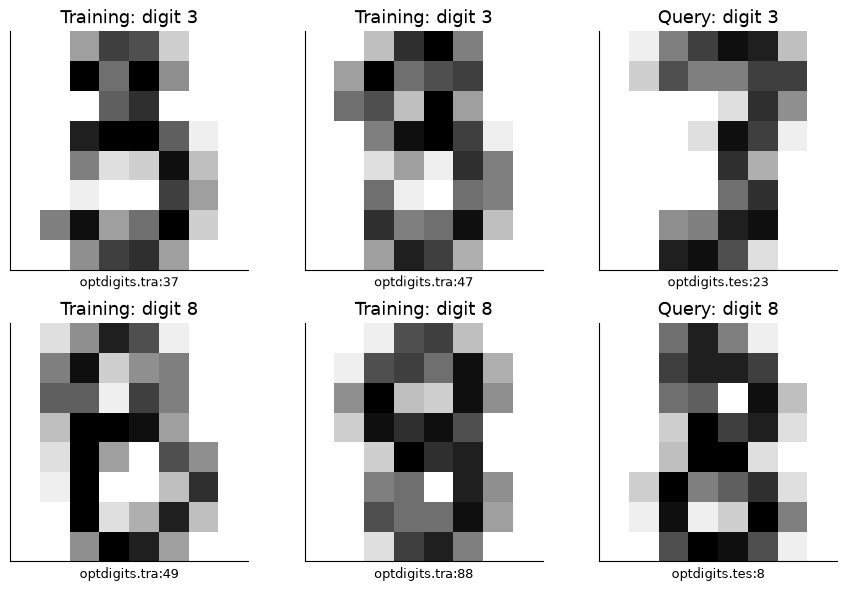

In [2]:
dm_fig, dm_axes = dm_plt.subplots(2, 3, figsize=(9, 6))

for dm_row, dm_label in enumerate((0, 1)):
    ids = dm_torch.nonzero(dm_train['y'] == dm_label).flatten()[:2]
    q = dm_torch.nonzero(query['y'] == dm_label).flatten()[0]
    for dm_ax, dm_split, dm_i, role in zip(dm_axes[dm_row], [dm_train, dm_train, query], [*ids, q], ['Training', 'Training', 'Query']):
        dm_ax.imshow(dm_split['images'][dm_i], cmap='gray_r', vmin=0, vmax=1)
        dm_ax.set_title(f"{role}: digit {dm_split['digit'][dm_i].item()}")
        dm_ax.set_xlabel(dm_split['ids'][dm_i], fontsize=9)
        dm_ax.set_xticks([])
        dm_ax.set_yticks([])

dm_show_figure(dm_fig, 'datamodel_images')

## 1️⃣ Turn training into a supervised learning problem

Write the training pool as $S=\{z_1,\ldots,z_n\}$. For a subset $S'$, let
$m\in\{0,1\}^n$ be its membership mask. The learning algorithm $A$ trains a
classifier on $S'$; for a fixed target $x$, its output is $f_A(x;S')$.

Our regression examples are now pairs $(m,f_A(x;S'))$. Each **row** is one
independently trained classifier. Each **column** of $m$ corresponds to one
original training image. Training one classifier supplies outputs for every
query, so the expensive work is shared across query-specific datamodels.

We sample uniformly from subsets of size $k=\alpha n$, as in the paper. Independent
Bernoulli inclusion would vary subset size; it is a different sampling distribution.

### Exercise - sample fixed-size training subsets

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a boolean tensor of shape `[models, training_images]`. Every row must contain exactly `size` true entries. Use a local CPU generator so this function does not change the global random state.

Predict how many memberships each row and each image column should have; which quantity is fixed and which varies?

In [3]:
def sample_subsets(n: int, size: int, count: int, seed: int) -> dm_Tensor:
    """Uniform fixed-size membership masks, one independent permutation per row."""
    if not 0 < size < n or count < 1:
        raise ValueError('Use a nonempty proper subset and a positive sample count.')
    generator = dm_torch.Generator(device='cpu').manual_seed(seed)
    masks = dm_torch.zeros(count, n, dtype=dm_torch.bool)
    for row in range(count):
        included = dm_torch.randperm(n, generator=generator)[:size]
        masks[row, included] = True
    return masks

dm_tests.test_sample_subsets(sample_subsets)

All tests in test_sample_subsets passed!


<details>
<summary>Help - where should I start?</summary>

The first `size` positions of a uniformly random permutation form a uniform subset. Draw a new permutation for every model. Do not use a sliding window through a single permutation.

</details>

<details>
<summary>Expected output</summary>

The test checks all twenty possible size-three subsets of six items, their approximate frequencies, and exact reproducibility for a fixed seed.

</details>

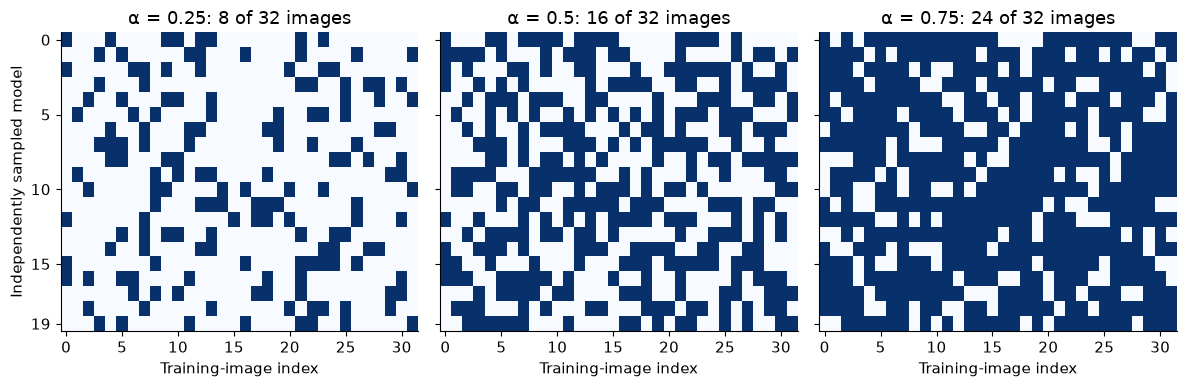

In [4]:
dm_fig, dm_axes = dm_plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for dm_ax, fraction in zip(dm_axes, (0.25, 0.5, 0.75)):
    masks = sample_subsets(32, int(32 * fraction), 20, 1610)
    dm_ax.imshow(masks, cmap='Blues', vmin=0, vmax=1, aspect='auto', interpolation='nearest')
    dm_ax.set_title(f'α = {fraction}: {int(32 * fraction)} of 32 images')
    dm_ax.set_xlabel('Training-image index')

dm_axes[0].set_ylabel('Independently sampled model')

dm_axes[0].set_yticks([0, 5, 10, 15, 19])

dm_show_figure(dm_fig, 'datamodel_membership')

### Which output should the datamodel predict?

Correct/incorrect is a useful decision but discards how close we are to its
boundary. The paper uses the **correct-class margin**:

$$f_A(x;S') = h_y(x)-\max_{c\ne y}h_c(x),$$

where $h_c$ is the classifier's logit for class $c$. Positive means the true
class is strictly ahead, zero is a tie, and negative means another class wins.
Adding the same constant to every logit changes neither the margin nor the
prediction. A probability difference is not the same quantity.

### Exercise - compute the correct-class margin

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Support logits shaped `[..., queries, classes]` and one integer label per query. Return `[..., queries]`, preserving every model/batch axis. Do not modify the input tensor.

Predict the correct-class margin when the correct logit ties the largest competitor. How should leading batch axes survive?

In [5]:
def correct_class_margins(logits: dm_Tensor, labels: dm_Tensor) -> dm_Tensor:
    """True-class logit minus the largest other logit; preserve leading axes."""
    if logits.ndim < 2 or logits.shape[-1] < 2 or labels.shape != (logits.shape[-2],):
        raise ValueError('Expected logits [..., queries, classes] and labels [queries].')
    if labels.dtype != dm_torch.int64 or (labels < 0).any() or (labels >= logits.shape[-1]).any():
        raise ValueError('Labels must index valid classes.')
    index = labels.expand(*logits.shape[:-1]).unsqueeze(-1)
    correct = logits.gather(-1, index).squeeze(-1)
    incorrect = logits.scatter(-1, index, -dm_torch.inf).amax(-1)
    return correct - incorrect

dm_tests.test_correct_class_margins(correct_class_margins)

All tests in test_correct_class_margins passed!


<details>
<summary>Help - where should I start?</summary>

Gather the true-class logit, then exclude that class before finding the maximum competitor. Setting it to zero is wrong when all logits are negative; use negative infinity in a separate tensor.

</details>

<details>
<summary>Expected output</summary>

The fixture returns `[[4, 1], [0, -1]]`. It includes a tie, negative logits and a common logit shift.

</details>

## 2️⃣ Fit a simple surrogate to a complicated operation

For each query fit $g(m)=b+m^Tw$, with one coefficient per training image. The
target remains the output of a fully trained classifier; we are not assuming
the classifier parameters themselves are linear in membership.

We minimize an independent Lasso objective for each query:

$$J(w,b)=\frac{1}{2M}\sum_{r=1}^M (b+m_r^Tw-y_r)^2+\lambda\|w\|_1.$$

The bias is unpenalized. Center $X$ and $Y$ using **training-row means** to remove
it from the optimization, then recover $b=\bar y-\bar m^Tw$. Do not center a
validation or test set using its own mean. Our squared-error factor is half
the one in the paper's equation 8, so equivalent regularization uses half its
$\lambda$.

The L1 term can set coefficients exactly to zero. This is a modeling preference,
not a guarantee that the data will support a sparse explanation.

**Common bug:** centering validation masks or responses with their own means
changes the predictor at evaluation time. Save the training means and recover
one intercept from them; then apply that same fitted function to every split.

### Exercise - implement soft thresholding

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the proximal map of the L1 penalty, allowing a scalar or broadcastable nonnegative threshold. Try deriving it by considering positive, zero and negative solutions separately.

Sketch the soft-threshold curve for two penalties and predict its zero interval.

In [6]:
def soft_threshold(values: dm_Tensor, threshold: dm_Tensor | float) -> dm_Tensor:
    """Proximal map for a nonnegative elementwise L1 penalty."""
    threshold = dm_torch.as_tensor(threshold, dtype=values.dtype, device=values.device)
    if not dm_torch.isfinite(threshold).all() or (threshold < 0).any():
        raise ValueError('Thresholds must be finite and nonnegative.')
    return values.sign() * (values.abs() - threshold).clamp_min(0)

dm_tests.test_soft_threshold(soft_threshold)

All tests in test_soft_threshold passed!


<details>
<summary>Help - where should I start?</summary>

The scalar minimizer of $(u-v)^2/2+\tau|u|$ is $\operatorname{sign}(v)\max(|v|-\tau,0)$. Thresholding the magnitude and restoring the sign avoids separate update branches.

</details>

<details>
<summary>Expected output</summary>

At threshold one, `[-3, -1, 0, 1, 3]` becomes `[-2, 0, 0, 0, 2]`. An independent grid search checks the scalar minimizer.

</details>

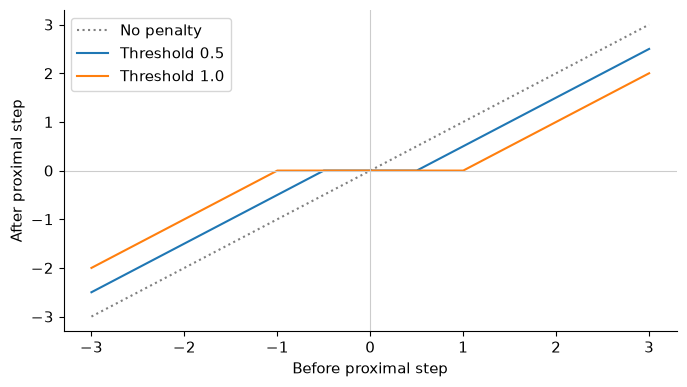

In [7]:
dm_values = dm_torch.linspace(-3, 3, 301, dtype=DTYPE)

dm_fig, dm_ax = dm_plt.subplots(figsize=(7, 4))

dm_ax.plot(dm_values, dm_values, ':', color='0.5', label='No penalty')

for threshold in (0.5, 1.0):
    dm_ax.plot(dm_values, soft_threshold(dm_values, threshold), label=f'Threshold {threshold}')

dm_ax.set(xlabel='Before proximal step', ylabel='After proximal step')

dm_ax.axhline(0, color='0.8', linewidth=0.8)

dm_ax.axvline(0, color='0.8', linewidth=0.8)

dm_ax.legend()

dm_show_figure(dm_fig, 'datamodel_soft_threshold')

### How do we know the solver has finished?

With centered inputs, define $G=X_c^TX_c/M$, $C=X_c^TY_c/M$ and
$g=Gw-C$. For an optimum, every nonzero coordinate must satisfy
$g_j=-\lambda\operatorname{sign}(w_j)$, while each zero coordinate must satisfy
$|g_j|\leq\lambda$. These are the KKT conditions. Convexity makes them
sufficient for a global optimum, although the coefficients need not be unique.

We will report the largest violation. A small change between two iterates alone
does not establish these conditions: an excessively small step can barely move
an incorrect answer.

### Exercise - measure the objective and check stationarity

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Return one objective and one maximum KKT violation per target. `weights` has shape `[training_images, targets]`; each target has its own penalty. For the KKT function, `gram` and `cross` already use centered training rows.

Predict the KKT violation for a zero versus nonzero coefficient with the same gradient.

In [8]:
def lasso_objective(x: dm_Tensor, y: dm_Tensor, weights: dm_Tensor, bias: dm_Tensor, penalty: dm_Tensor) -> dm_Tensor:
    """One objective per target: mean squared error / 2 plus lambda * L1."""
    residual = x @ weights + bias - y
    return residual.square().mean(0) / 2 + penalty * weights.abs().sum(0)


def lasso_kkt(gram: dm_Tensor, cross: dm_Tensor, weights: dm_Tensor, penalty: dm_Tensor) -> dm_Tensor:
    """Maximum stationarity violation per target for centered Lasso."""
    gradient = gram @ weights - cross
    active = (gradient + penalty * weights.sign()).abs()
    inactive = (gradient.abs() - penalty).clamp_min(0)
    return dm_torch.where(weights != 0, active, inactive).amax(0)

dm_tests.test_lasso_objective(lasso_objective)

dm_tests.test_lasso_kkt(lasso_kkt)

All tests in test_lasso_objective passed!
All tests in test_lasso_kkt passed!


<details>
<summary>Help - where should I start?</summary>

For a nonzero coefficient use `abs(gradient + penalty * sign(weight))`. For a zero coefficient only the excess of `abs(gradient)` over the penalty violates stationarity. The intercept contributes squared error but never an L1 penalty.

</details>

<details>
<summary>Expected output</summary>

The objective fixture gives `[0.2, 3.15]`. The exact orthogonal-design optimum has zero KKT violation; deliberate errors produce `[1.3, 0.5]`.

</details>

## 3️⃣ Solve all target regressions together

A proximal-gradient step is

$$w^+=\operatorname{soft\_threshold}\left(w-\frac{Gw-C}{L},\frac{\lambda}{L}\right),$$

where $L$ is the largest eigenvalue of $G$. The same $G$ is shared by every
target, so one matrix multiplication advances all regressions. This batching
does not share their coefficients or penalties.

We use accelerated steps: extrapolate from the last two iterates with
$t^+=(1+\sqrt{1+4t^2})/2$ and coefficient $(t-1)/t^+$. If
$(z-w^+)^T(w^+-w)>0$, restart that target's acceleration. Here $z$ is the
extrapolated point. The restart is an optimization choice; the checked KKT
condition still determines whether to accept the result.

The exercise is deliberately substantial. Start with ordinary proximal gradient,
check the orthogonal fixture, then add acceleration. A zero Gram matrix needs
only the mean-response intercept.

### Exercise - fit Lasso with a checked optimum

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 30-45 minutes on this exercise.
> ```

Fit centered multi-target Lasso, recover the intercept, and return weights, bias, KKT residuals, step count and a two-column history of checked steps and the largest residual. Use `soft_threshold` and `lasso_kkt`. Stop only when all residuals satisfy `tolerance`; raise an error if the step limit is reached.

Forecast how the objective and maximum KKT residual should evolve; distinguish convergence from predictive usefulness.

In [9]:
def fit_lasso(x: dm_Tensor, y: dm_Tensor, penalty: dm_Tensor, initial: dm_Tensor | None=None, tolerance: float=1e-08, max_steps: int=20000) -> dict[str, dm_Tensor | int]:
    """Accelerated proximal gradient with target-wise adaptive restart.

    Center using training means only. The Gram matrix is shared by all targets;
    each target still has its own coefficients, penalty and acceleration state.
    A checked KKT residual, not an iteration count, certifies convergence.
    """
    if x.ndim != 2 or y.ndim != 2 or len(x) != len(y) or (len(x) < 1):
        raise ValueError('Expected x [models, examples] and y [models, targets].')
    if penalty.shape != (y.shape[1],) or (penalty < 0).any() or (not dm_torch.isfinite(penalty).all()):
        raise ValueError('Provide one finite nonnegative penalty per target.')
    if not dm_torch.isfinite(x).all() or not dm_torch.isfinite(y).all():
        raise ValueError('Regression inputs must be finite.')
    if not dm_math.isfinite(tolerance) or tolerance <= 0 or max_steps < 1:
        raise ValueError('Use a positive finite tolerance and positive step limit.')
    x_mean, y_mean = (x.mean(0), y.mean(0))
    xc, yc = (x - x_mean, y - y_mean)
    gram, cross = (xc.T @ xc / len(x), xc.T @ yc / len(x))
    lipschitz = dm_torch.linalg.eigvalsh(gram)[-1]
    shape = (x.shape[1], y.shape[1])
    weights = x.new_zeros(shape) if initial is None else initial.clone()
    if weights.shape != shape or not dm_torch.isfinite(weights).all():
        raise ValueError('Initial coefficients have the wrong shape or nonfinite entries.')
    if lipschitz <= dm_torch.finfo(x.dtype).eps:
        weights.zero_()
        residual = lasso_kkt(gram, cross, weights, penalty)
        return dict(weights=weights, bias=y_mean, kkt=residual, steps=0, history=dm_torch.cat([x.new_zeros(1), residual.max().reshape(1)])[None])
    extrapolated = weights.clone()
    momentum_time = x.new_ones(y.shape[1])
    history = []
    for step in range(1, max_steps + 1):
        gradient = gram @ extrapolated - cross
        updated = soft_threshold(extrapolated - gradient / lipschitz, penalty / lipschitz)
        next_time = (1 + dm_torch.sqrt(1 + 4 * momentum_time.square())) / 2
        restart = ((extrapolated - updated) * (updated - weights)).sum(0) > 0
        acceleration = dm_torch.where(restart, 0, (momentum_time - 1) / next_time)
        extrapolated = updated + acceleration * (updated - weights)
        momentum_time = dm_torch.where(restart, 1, next_time)
        weights = updated
        if step == 1 or step % 10 == 0 or step == max_steps:
            residual = lasso_kkt(gram, cross, weights, penalty)
            history.append(dm_torch.stack([x.new_tensor(step), residual.max()]))
            if (residual <= tolerance).all():
                return dict(weights=weights, bias=y_mean - x_mean @ weights, kkt=residual, steps=step, history=dm_torch.stack(history))
    raise RuntimeError(f'Lasso did not converge: maximum KKT residual {residual.max().item():.3g}.')

dm_tests.test_fit_lasso(fit_lasso)

All tests in test_fit_lasso passed!


<details>
<summary>Help - where should I start?</summary>

Center once, form `gram` and `cross`, and use `torch.linalg.eigvalsh(gram)[-1]` for the step scale. Maintain one acceleration time per target. Check KKT at step one, every ten steps and the final allowed step. A warm start is allowed for the regression coefficients; classifier retraining later always starts from zero.

</details>

<details>
<summary>Expected output</summary>

The test compares predictions and objective values with scikit-learn coordinate descent, including a fixed-cardinality design with non-unique coefficient offsets. Passing does not depend on selecting exactly the same representative coefficients.

</details>

## 4️⃣ Choose regularization without reading test responses

For centered training rows, $\lambda_{\max}=\max_j|C_j|$ makes the zero weight
vector optimal. Fit a descending path from that value to $10^{-4}$ of it. Each
query gets its own scale and its own validation choice. On an exact tie, keep
the earlier, more regularized path point.

The regression train/validation/test split is a split over **trained models**.
All three can evaluate the same fixed query image. Reusing a model in two splits
would leak its response, even if the response was saved under a different filename.

We retain the whole path. A selected endpoint is evidence that the best penalty
may lie beyond the tested range; it is not proof that we found the globally
best hyperparameter.

### Exercise - fit and validate a regularization path

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Fit every penalty on the training subset/output pairs, warm-starting from the previous path point. Compute validation MSE per query and select its minimum. Return the complete path as well as the selected weight and bias for each query. The function deliberately has no test-response argument.

Which penalty wins validation, and what information must remain unopened? Predict how correlated membership columns affect coefficients.

In [10]:
def fit_datamodel_path(x_train: dm_Tensor, y_train: dm_Tensor, x_val: dm_Tensor, y_val: dm_Tensor, fractions: dm_Tensor) -> dict[str, dm_Tensor]:
    """Fit every path point on train rows, then select per target on validation."""
    if fractions.ndim != 1 or len(fractions) < 1 or (not dm_torch.isfinite(fractions).all()):
        raise ValueError('Use a nonempty finite path of penalty fractions.')
    if (fractions <= 0).any() or (fractions > 1).any() or (fractions[1:] > fractions[:-1]).any():
        raise ValueError('Penalty fractions must descend within (0, 1].')
    if x_val.shape[1:] != x_train.shape[1:] or y_val.shape != (len(x_val), y_train.shape[1]):
        raise ValueError('Validation masks and targets must align with the training axes.')
    xc, yc = (x_train - x_train.mean(0), y_train - y_train.mean(0))
    lambda_max = (xc.T @ yc / len(x_train)).abs().amax(0)
    weights, biases, residuals, steps, validation, penalties = ([], [], [], [], [], [])
    initial = None
    for fraction in fractions:
        penalty = fraction * lambda_max
        fit = fit_lasso(x_train, y_train, penalty, initial=initial)
        initial = fit['weights']
        weights.append(fit['weights'])
        biases.append(fit['bias'])
        residuals.append(fit['kkt'])
        steps.append(fit['steps'])
        penalties.append(penalty)
        prediction = x_val @ fit['weights'] + fit['bias']
        validation.append((prediction - y_val).square().mean(0))
    weights, biases = (dm_torch.stack(weights), dm_torch.stack(biases))
    validation = dm_torch.stack(validation)
    selected = validation.argmin(0)
    targets = dm_torch.arange(y_train.shape[1], device=x_train.device)
    return dict(weights=weights, bias=biases, penalty=dm_torch.stack(penalties), kkt=dm_torch.stack(residuals), steps=dm_torch.tensor(steps), validation_mse=validation, selected=selected, selected_weights=weights[selected, :, targets].T, selected_bias=biases[selected, targets])

dm_tests.test_fit_datamodel_path(fit_datamodel_path)

All tests in test_fit_datamodel_path passed!


<details>
<summary>Help - where should I start?</summary>

Use training means for `lambda_max`. Stack weights as `[path, images, targets]` and validation losses as `[path, targets]`. Advanced indexing can transpose selected axes unexpectedly; explicitly check that selected weights are `[images, targets]`.

</details>

<details>
<summary>Expected output</summary>

The synthetic test chooses path indices `[2, 0]`: a predictive target prefers less shrinkage, while a constant target ties and chooses the first index. Changing validation labels must leave every fitted path coefficient unchanged.

</details>

### Try It Yourself — when is a linear datamodel insufficient?

This small, exact fixture separates solver error from model misspecification.
Its output is a sparse linear membership function plus an optional interaction.
The interaction makes one training example's effect depend on another's presence.

Change `INTERACTION` from zero to one or two, or change `SUBSET_SIZE`. The seed
and row splits stay fixed. Compare held-out predictions with the identity line
and the mean-response baseline. Stronger interactions cannot be repaired merely
by driving the Lasso optimization residual closer to zero.

Forecast held-out error before increasing the interaction while keeping the linear solver fixed.

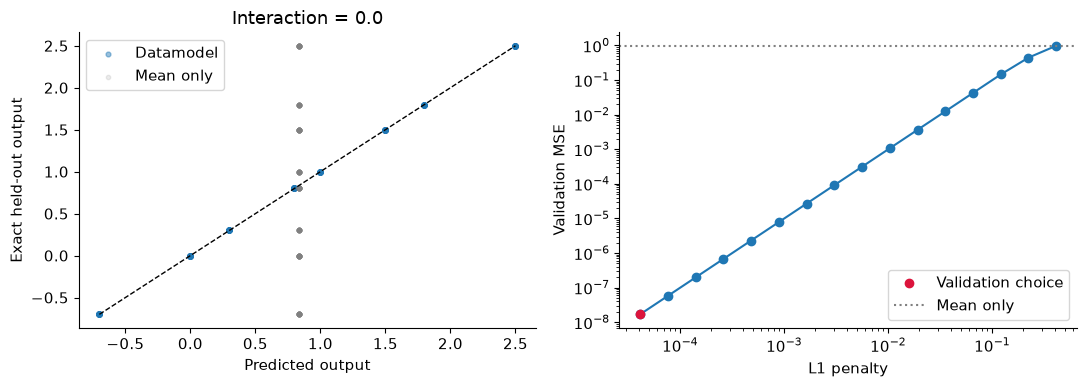

In [11]:
INTERACTION = 0.0

SUBSET_SIZE = 12

fixture_masks = [sample_subsets(24, SUBSET_SIZE, count, seed).double() for count, seed in ((384, 31), (128, 32), (256, 33))]

fixture_weights = dm_torch.zeros(24, 1, dtype=DTYPE)

fixture_weights[[0, 4, 11], 0] = dm_torch.tensor([1.5, -1.0, 0.7], dtype=DTYPE)

def fixture_response(x):
    interaction = (x[:, 1] - x[:, 2]) * (x[:, 7] - x[:, 8])
    return 0.3 + x @ fixture_weights + INTERACTION * interaction[:, None]

fixture_y = [fixture_response(x) for x in fixture_masks]

fixture_path = fit_datamodel_path(*[fixture_masks[0], fixture_y[0], fixture_masks[1], fixture_y[1]], dm_torch.logspace(0, -4, 16, dtype=DTYPE))

fixture_pred = fixture_masks[2] @ fixture_path['selected_weights'] + fixture_path['selected_bias']

dm_fig, dm_axes = dm_plt.subplots(1, 2, figsize=(11, 4))

dm_axes[0].scatter(fixture_pred[:, 0], fixture_y[2][:, 0], s=12, alpha=0.45, label='Datamodel')

dm_axes[0].scatter(dm_torch.full_like(fixture_y[2][:, 0], fixture_y[0].mean()), fixture_y[2][:, 0], s=10, alpha=0.15, color='0.5', label='Mean only')

bounds = [float(fixture_y[2].min()), float(fixture_y[2].max())]

dm_axes[0].plot(bounds, bounds, 'k--', linewidth=1)

dm_axes[0].set(xlabel='Predicted output', ylabel='Exact held-out output', title=f'Interaction = {INTERACTION}')

dm_axes[0].legend()

dm_axes[1].plot(fixture_path['penalty'][:, 0], fixture_path['validation_mse'][:, 0], 'o-')

dm_chosen = fixture_path['selected'][0]

dm_axes[1].scatter(fixture_path['penalty'][dm_chosen, 0], fixture_path['validation_mse'][dm_chosen, 0], color='crimson', zorder=3, label='Validation choice')

dm_axes[1].axhline(float((fixture_y[1] - fixture_y[0].mean()).square().mean()), color='0.5', linestyle=':', label='Mean only')

dm_axes[1].set(xscale='log', yscale='log', xlabel='L1 penalty', ylabel='Validation MSE')

dm_axes[1].legend()

dm_show_figure(dm_fig, 'datamodel_fixture_play')

## 5️⃣ A coefficient offset you cannot identify

Every fixed-size mask obeys $m^T\mathbf{1}=k$. Consequently,

$$m^T(w+c\mathbf{1})+(b-kc)=m^Tw+b.$$

The same-size data cannot distinguish these coefficient/bias pairs. An L1
penalty prefers representatives with a small absolute coefficient sum, but that
choice does not identify an underlying causal offset. For a different size
$k'$, the predictions differ by $(k'-k)c$.

Try deriving the difference for removing $r$ images from the full pool: the
predicted change shifts by $-rc$. Rankings are unchanged. A method can therefore
agree about **which** images to remove while disagreeing about **how much** the
margin should change.

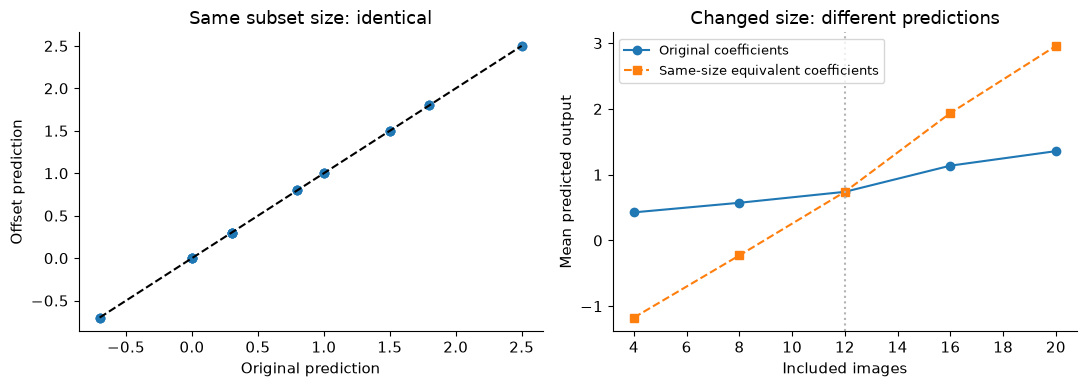

In [12]:
gauge_masks = sample_subsets(24, 12, 48, 615).double()

gauge_w = fixture_path['selected_weights'][:, 0]

gauge_b = fixture_path['selected_bias'][0]

offset = 0.2

original = gauge_masks @ gauge_w + gauge_b

shifted = gauge_masks @ (gauge_w + offset) + gauge_b - 12 * offset

dm_torch.testing.assert_close(original, shifted)

dm_sizes = [4, 8, 12, 16, 20]

means, shifted_means = ([], [])

for size in dm_sizes:
    masks = sample_subsets(24, size, 48, 615).double()
    means.append(float((masks @ gauge_w + gauge_b).mean()))
    shifted_means.append(float((masks @ (gauge_w + offset) + gauge_b - 12 * offset).mean()))

dm_fig, dm_axes = dm_plt.subplots(1, 2, figsize=(11, 4))

dm_axes[0].scatter(original, shifted, alpha=0.6)

dm_axes[0].plot([float(original.min()), float(original.max())], [float(original.min()), float(original.max())], 'k--')

dm_axes[0].set(xlabel='Original prediction', ylabel='Offset prediction', title='Same subset size: identical')

dm_axes[1].plot(dm_sizes, means, 'o-', label='Original coefficients')

dm_axes[1].plot(dm_sizes, shifted_means, 's--', label='Same-size equivalent coefficients')

dm_axes[1].axvline(12, color='0.7', linestyle=':')

dm_axes[1].set(xlabel='Included images', ylabel='Mean predicted output', title='Changed size: different predictions')

dm_axes[1].legend(fontsize=9)

dm_show_figure(dm_fig, 'datamodel_gauge')

### Exercise - compare datamodel directions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Treat each target’s weights as an embedding and return a `[targets, targets]` cosine-similarity matrix. Remove each target’s mean coefficient first so the result is invariant to arbitrary common offsets. Give an all-constant vector zero similarity rather than dividing by zero.

Predict whether adding a constant to every training-image coefficient changes centered similarity or same-size subset predictions.

In [13]:
def centered_weight_similarity(weights: dm_Tensor) -> dm_Tensor:
    """Cosine similarity of target datamodels, invariant to target-wise offsets."""
    centered = weights - weights.mean(0, keepdim=True)
    norms = centered.norm(dim=0)
    normalized = centered / norms.clamp_min(dm_torch.finfo(weights.dtype).eps)
    return normalized.T @ normalized

dm_tests.test_centered_weight_similarity(centered_weight_similarity)

All tests in test_centered_weight_similarity passed!


<details>
<summary>Help - where should I start?</summary>

The training-image axis is the first axis. Center along it, normalize each column, and multiply normalized columns by one another. Centered cosine is our explicitly chosen comparison, not a claim that the paper used this exact normalization.

</details>

<details>
<summary>Expected output</summary>

The fixture includes identical, opposite and constant directions. Adding a separate offset to every target leaves the matrix unchanged.

</details>

## 6️⃣ Propose a deletion, then test it

For a query with weight vector $w$, removing indices $R$ changes the datamodel
prediction by $-\sum_{i\in R}w_i$. To reduce the margin, remove the largest
weights. This is a proposal, not an observed effect. We must train on $S\setminus R$
to find out what happens.

Removing many examples of one class changes the class balance. Our random
controls match the selected deletion's number of threes and eights exactly.
They answer whether these particular images matter beyond that class composition.
They may overlap the selected set by chance; do not exclude overlaps artificially.

### Exercise - select supportive images and match random controls

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Select the largest `budget` scores with stable source-order ties. Then sample random index sets without replacement, matching the selected set’s count in every observed class. Return sorted indices for easy comparison; do not use the query outcome to choose controls.

Which source IDs win a tie, and what class counts must every random removal preserve?

In [14]:
def select_supportive(scores: dm_Tensor, budget: int) -> dm_Tensor:
    """Indices with largest scores, breaking ties by the original source order."""
    if scores.ndim != 1 or not dm_torch.isfinite(scores).all() or (not 0 <= budget < len(scores)):
        raise ValueError('Provide finite scores and a budget leaving at least one example.')
    return dm_torch.argsort(scores, descending=True, stable=True)[:budget].sort().values


def matched_random_removals(labels: dm_Tensor, selected: dm_Tensor, count: int, seed: int) -> dm_Tensor:
    """Random index sets matching the selected set's count in every class."""
    if labels.ndim != 1 or labels.dtype != dm_torch.int64 or selected.dtype != dm_torch.int64:
        raise ValueError('Labels and selected indices must be integer vectors.')
    if selected.ndim != 1 or len(selected.unique()) != len(selected) or count < 1:
        raise ValueError('Use distinct selected indices and a positive control count.')
    if (selected < 0).any() or (selected >= len(labels)).any():
        raise ValueError('Selected indices are outside the training pool.')
    generator = dm_torch.Generator(device='cpu').manual_seed(seed)
    sets = []
    for _ in range(count):
        pieces = []
        for label in labels.unique(sorted=True):
            candidates = dm_torch.nonzero(labels == label).flatten()
            number = int((labels[selected] == label).sum())
            permutation = dm_torch.randperm(len(candidates), generator=generator)
            pieces.append(candidates[permutation[:number]])
        sets.append(dm_torch.cat(pieces).sort().values)
    return dm_torch.stack(sets)

dm_tests.test_select_supportive(select_supportive)

dm_tests.test_matched_random_removals(matched_random_removals)

All tests in test_select_supportive passed!
All tests in test_matched_random_removals passed!


<details>
<summary>Help - where should I start?</summary>

Sort the scores descending with `stable=True`. For each random replicate, independently permute the available indices within each class and take the required count. Matching labels means matching the labels actually used for training.

</details>

<details>
<summary>Expected output</summary>

The selection fixture keeps indices `[1, 4]`. Every random control in the three-class fixture removes exactly `[1, 2, 1]` examples from the three classes.

</details>

## 7️⃣ Train the real subset models

The classifier is the regularized logistic model from 16.9: mean cross-entropy
plus $0.02\|\theta\|^2/2$, including the bias. Every subset fit starts at zero
and converges to a gradient infinity norm below $10^{-10}$. Batching accelerates
independent fits; it does not continue one model's training inside another.

This choice isolates variation due to training subsets. There is no random
initialization or stochastic optimization noise floor to estimate here. The
paper's deep-network experiments have both sources of variation; their procedure
averages multiple trainings when estimating expected outputs.

For each $\alpha\in\{0.25,0.5,0.75\}$ we fit 1,024 training-subset models and
128 validation-subset models. Another 256 models per fraction are held out for
evaluation. Each fit supplies margins for all 64 queries. The datamodel never
receives pixels as regression inputs—only membership bits.

The following driver connects your functions. The classifier optimizer is the
only reused method, linked and taught in 16.9. All subset sampling, regression,
selection, prediction and intervention logic is visible below.

In [15]:
from chapter16_shapley_attribution_baselines.exercises.part9_influence_and_tracin.attribution_methods import fit_weighted_logistic

FRACTIONS = (0.25, 0.5, 0.75)

BUDGETS = (2, 8, 16, 32)

In [16]:
def make_designs(methods) -> dict:
    """Build and check the prescribed mask splits without fitting any classifier."""
    designs = {}
    for a, fraction in enumerate(FRACTIONS):
        sizes = (('train', 1024), ('validation', 128), ('test', 256))
        design = {name: methods.sample_subsets(128, int(fraction * 128), count, 161000 + 100 * a + split) for split, (name, count) in enumerate(sizes)}
        together = dm_torch.cat(list(design.values()))
        if together.unique(dim=0).shape[0] != len(together):
            raise ValueError('A duplicate subset crossed or appeared within the prescribed splits.')
        designs[fraction] = design
    return designs

def refit_masks(train: dict, masks: dm_Tensor) -> dict[str, dm_Tensor]:
    """Batched independent classifier fits using the optimizer taught in 16.9."""
    if masks.ndim != 2 or masks.shape[1] != len(train['x']) or masks.dtype != dm_torch.bool:
        raise ValueError('Provide boolean training membership masks.')
    if (masks.sum(1) == 0).any():
        raise ValueError('A model cannot be trained on an empty subset.')
    weights, gradients, objectives = ([], [], [])
    for batch in masks.split(128):
        fit = fit_weighted_logistic(train['x'], train['y'], batch.double(), l2=0.02)
        weights.append(fit['theta'])
        gradients.append(fit['gradient_norms'][-1])
        objectives.append(fit['objective'])
    return dict(theta=dm_torch.cat(weights), gradient_norm=dm_torch.cat(gradients), objective=dm_torch.cat(objectives))

def model_margins(fit: dict, query: dict, methods) -> dm_Tensor:
    logit = fit['theta'] @ query['x'].T
    two_class_logits = dm_torch.stack([dm_torch.zeros_like(logit), logit], dim=-1)
    return methods.correct_class_margins(two_class_logits, query['y'])

def least_squares_datamodel(x: dm_Tensor, y: dm_Tensor) -> dict[str, dm_Tensor]:
    """Unpenalized minimum-norm baseline; center on training rows only."""
    xc, yc = (x - x.mean(0), y - y.mean(0))
    weights = dm_torch.linalg.lstsq(xc, yc, driver='gelsd').solution
    return dict(weights=weights, bias=y.mean(0) - x.mean(0) @ weights)

### What will count as a useful prediction?

We compare Lasso with an intercept-only predictor, minimum-norm least squares,
and a control that permutes the association between training masks and responses.
The permutation preserves the response values, but destroys which subset produced
each one. It receives the same validation procedure as Lasso.

At $\alpha=0.5$ we also use the first 64, 128, 256 and 512 training-subset models.
This gives a sample-complexity curve without retraining or choosing favorable
samples. Every point uses the same separate validation and test subsets.

The deletion experiment uses 24 fixed queries: the first twelve source-ordered
queries in each class. Four rankings propose deletions: one datamodel for each
fraction and signed pixel cosine similarity. Every ranking/query/budget has
sixteen class-matched random controls. We construct all 6,528 masks before
reading their outcomes.

In [17]:
def fit_response_models(x: dm_Tensor, y: dm_Tensor, xv: dm_Tensor, yv: dm_Tensor, methods) -> dict:
    """Lasso and controls see only their fit and validation subset responses."""
    penalties = dm_torch.logspace(0, -4, 16, dtype=x.dtype)
    result = {'lasso': methods.fit_datamodel_path(x, y, xv, yv, penalties)}
    permutation = dm_torch.randperm(len(y), generator=dm_torch.Generator().manual_seed(161440))
    result['permuted'] = methods.fit_datamodel_path(x, y[permutation], xv, yv, penalties)
    result['permutation'] = permutation
    result['least_squares'] = least_squares_datamodel(x, y)
    result['intercept'] = y.mean(0)
    return result

def build_deletion_masks(train: dict, query: dict, responses: dict, methods) -> dict:
    """Freeze all selected and matched control sets before seeing refit outcomes."""
    query_ids = dm_torch.cat([dm_torch.nonzero(query['y'] == label).flatten()[:12] for label in (0, 1)]).sort().values
    pixel = dm_torch.nn.functional.normalize(train['x'][:, :64], dim=1)
    target_pixel = dm_torch.nn.functional.normalize(query['x'][:, :64], dim=1)
    pixel_scores = pixel @ target_pixel.T * dm_torch.where(train['y'][:, None] == query['y'][None], 1.0, -1.0)
    all_scores = [responses[a]['lasso']['selected_weights'] for a in FRACTIONS] + [pixel_scores]
    masks, target, budget_values, method_values, replicate, class_counts = ([], [], [], [], [], [])
    for method_index, scores in enumerate(all_scores):
        for position, q in enumerate(query_ids.tolist()):
            for budget in BUDGETS:
                selected = methods.select_supportive(scores[:, q], budget)
                seed = 162000 + 10000 * method_index + 100 * position + budget
                controls = methods.matched_random_removals(train['y'], selected, 16, seed)
                for rep, removed in enumerate(dm_torch.cat([selected[None], controls])):
                    mask = dm_torch.ones(len(train['y']), dtype=dm_torch.bool)
                    mask[removed] = False
                    masks.append(mask)
                    target.append(q)
                    budget_values.append(budget)
                    method_values.append(method_index)
                    replicate.append(rep - 1)
                    class_counts.append(dm_torch.bincount(train['y'][removed], minlength=2))
    return dict(masks=dm_torch.stack(masks), target=dm_torch.tensor(target), budget=dm_torch.tensor(budget_values), method=dm_torch.tensor(method_values), replicate=dm_torch.tensor(replicate), removed_class_counts=dm_torch.stack(class_counts), query_indices=query_ids, pixel_scores=pixel_scores)

def prepare_study(train: dict, query: dict, designs: dict, methods, directory: dm_Path) -> dict:
    """Fit/validate datamodels and construct deletions; never fit test subsets."""
    directory.mkdir(parents=True, exist_ok=False)
    subset_fits, outputs, responses, learning = ({}, {}, {}, {})
    for fraction in FRACTIONS:
        fit = {name: refit_masks(train, designs[fraction][name]) for name in ('train', 'validation')}
        margins = {name: model_margins(value, query, methods) for name, value in fit.items()}
        x, xv = [designs[fraction][name].double() for name in ('train', 'validation')]
        y, yv = (margins['train'], margins['validation'])
        response = fit_response_models(x, y, xv, yv, methods)
        if fraction == 0.5:
            for count in (64, 128, 256, 512):
                learning[count] = fit_response_models(x[:count], y[:count], xv, yv, methods)
        subset_fits[fraction], outputs[fraction], responses[fraction] = (fit, margins, response)
    deletions = build_deletion_masks(train, query, responses, methods)
    result = dict(phase='FIT_VALIDATION_AND_DELETION_SELECTION_COMPLETE', designs=designs, subset_fits=subset_fits, margins=outputs, responses=responses, learning=learning, deletions=deletions, training_ids=train['ids'], query_ids=query['ids'], test_subset_responses_seen=False, counterfactual_responses_seen=False)
    dm_torch.save(result, directory / 'prepared.pt')
    return result

Before model fitting, forecast relative held-out performance of Lasso, least squares, mean-only and permuted-response controls.

In [18]:
method_names = ['sample_subsets', 'correct_class_margins', 'fit_datamodel_path', 'select_supportive', 'matched_random_removals']

dm_methods = dm_SimpleNamespace(**{name: globals()[name] for name in method_names})

designs = make_designs(dm_methods)

NATIVE = dm_Path(dm_tempfile.mkdtemp(prefix='native-', dir=dm_OUTPUT)) / 'study'

dm_prepared = prepare_study(dm_train, query, designs, dm_methods, NATIVE)

dm_boundary = {'phase': dm_prepared['phase'], 'prepared_sha256': dm_hashlib.sha256((NATIVE / 'prepared.pt').read_bytes()).hexdigest(), 'test_subset_responses_seen': False, 'counterfactual_responses_seen': False}

(dm_OUTPUT / 'selection_boundary.json').write_text(dm_json.dumps(dm_boundary, indent=2) + '\n')

print('3,456 classifier fits complete. All paths and deletion masks fixed; test responses still unseen.')

3,456 classifier fits complete. All paths and deletion masks fixed; test responses still unseen.


### Inspect the validation path before opening the test responses

The left plot shows validation error relative to the mean-only baseline. The
middle plot shows the median number of nonzero coefficients; the right plot
shows which path points were selected. Bands describe variation across the 64
queries, not confidence intervals.

On this problem the selected explanations are mostly dense: the median count
is 126, 126 and 128 of 128 coefficients at the three fractions. Many queries
select the least-regularized endpoint. Keep that result. Lasso's sparsity prior
does not make a sparse explanation appropriate for every learning algorithm.

Predict whether the least validation error requires the sparsest solution; compare objectives and KKT residuals.

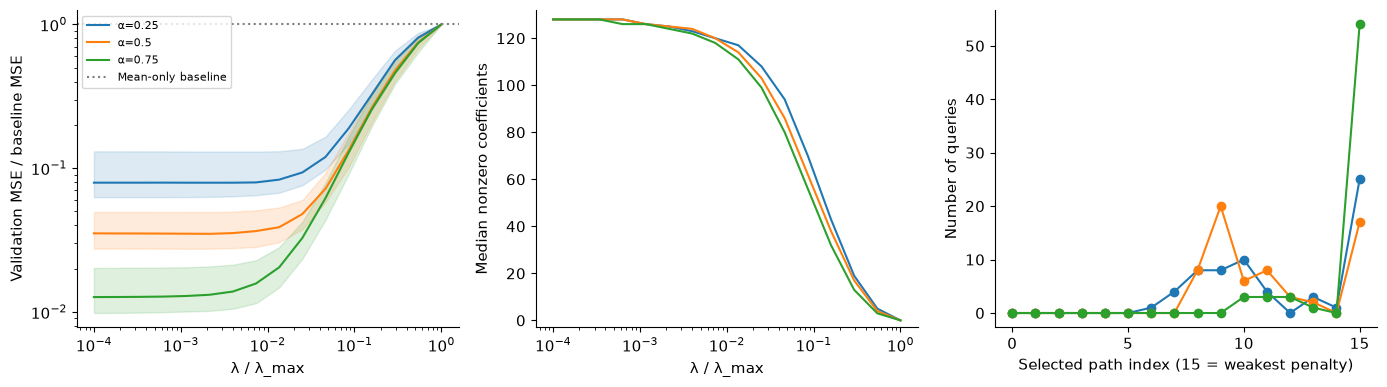

In [19]:
dm_fig, dm_axes = dm_plt.subplots(1, 3, figsize=(14, 4))

path_fractions = dm_torch.logspace(0, -4, 16, dtype=DTYPE)

for fraction, color in zip(FRACTIONS, ('C0', 'C1', 'C2')):
    response = dm_prepared['responses'][fraction]
    path = response['lasso']
    yv = dm_prepared['margins'][fraction]['validation']
    baseline = (yv - response['intercept']).square().mean(0)
    ratio = path['validation_mse'] / baseline
    dm_axes[0].plot(path_fractions, ratio.median(1).values, color=color, label=f'α={fraction}')
    dm_axes[0].fill_between(path_fractions, ratio.quantile(0.1, dim=1), ratio.quantile(0.9, dim=1), color=color, alpha=0.15)
    dm_axes[1].plot(path_fractions, (path['weights'] != 0).sum(1).double().median(1).values, color=color)
    dm_axes[2].plot(range(16), dm_torch.bincount(path['selected'], minlength=16), 'o-', color=color)

dm_axes[0].axhline(1, color='0.5', linestyle=':', label='Mean-only baseline')

dm_axes[0].set(xscale='log', yscale='log', xlabel='λ / λ_max', ylabel='Validation MSE / baseline MSE')

dm_axes[0].legend(fontsize=8)

dm_axes[1].set(xscale='log', xlabel='λ / λ_max', ylabel='Median nonzero coefficients', ylim=(-3, 132))

dm_axes[2].set(xlabel='Selected path index (15 = weakest penalty)', ylabel='Number of queries', xticks=[0, 5, 10, 15])

dm_show_figure(dm_fig, 'datamodel_validation_path')

## 8️⃣ Open the held-out subset results

Now train the held-out models and evaluate the frozen choices. There is no
regularization selection in this function. It also performs the full-pool and
counterfactual fits; their masks have already been fixed.

The main signature result is a prediction made from membership alone, compared
with the margin obtained after actual retraining. We first subtract each query's
test mean from both axes for plotting. This visualization removes between-query
offsets; it does **not** change predictions or evaluation metrics. Without this
view, a pooled correlation could mostly reflect that some digits are always easy.

In [20]:
def response_predictions(response: dict, masks: dm_Tensor) -> dict[str, dm_Tensor]:
    x = masks.double()
    predictions = {}
    for name in ('lasso', 'permuted'):
        model = response[name]
        predictions[name] = x @ model['selected_weights'] + model['selected_bias']
    model = response['least_squares']
    predictions['least_squares'] = x @ model['weights'] + model['bias']
    predictions['intercept'] = response['intercept'].expand(len(x), -1)
    return predictions

def dm_evaluate_study(prepared: dict, train: dict, query: dict, methods, directory: dm_Path) -> dict:
    """Retrain held-out subsets and frozen counterfactuals, with no model selection."""
    if prepared.get('phase') != 'FIT_VALIDATION_AND_DELETION_SELECTION_COMPLETE':
        raise ValueError('Complete all datamodel fitting and deletion selection before evaluation.')
    if prepared['training_ids'] != train['ids'] or prepared['query_ids'] != query['ids']:
        raise ValueError('Data row identity/order changed between preparation and evaluation.')
    if prepared['test_subset_responses_seen'] or prepared['counterfactual_responses_seen']:
        raise ValueError('The prepared experiment claims it already inspected evaluation outcomes.')
    tests, cross_fraction, learning_predictions = ({}, {}, {})
    for fraction in FRACTIONS:
        masks = prepared['designs'][fraction]['test']
        fit = refit_masks(train, masks)
        margin = model_margins(fit, query, methods)
        predictions = response_predictions(prepared['responses'][fraction], masks)
        tests[fraction] = dict(fit=fit, margin=margin, predictions=predictions)
        cross_fraction[fraction] = {source: response_predictions(prepared['responses'][source], masks)['lasso'] for source in FRACTIONS}
        if fraction == 0.5:
            for count, response in prepared['learning'].items():
                learning_predictions[count] = response_predictions(response, masks)
    base_fit = refit_masks(train, dm_torch.ones(1, len(train['y']), dtype=dm_torch.bool))
    base_margin = model_margins(base_fit, query, methods)[0]
    deletion = prepared['deletions']
    refits = refit_masks(train, deletion['masks'])
    all_margin = model_margins(refits, query, methods)
    rows = dm_torch.arange(len(all_margin))
    query_index = deletion['target']
    target_margin = all_margin[rows, query_index]
    prediction = []
    for fraction in FRACTIONS:
        weights = prepared['responses'][fraction]['lasso']['selected_weights']
        full_changes = -(~deletion['masks']).double() @ weights
        prediction.append(full_changes[rows, query_index])
    result = dict(phase='FROZEN_EVALUATION_COMPLETE', test=tests, cross_fraction=cross_fraction, learning_predictions=learning_predictions, base_fit=base_fit, base_margin=base_margin, counterfactual=dict(fit=refits, all_margin=all_margin, target_margin=target_margin, actual_change=target_margin - base_margin[query_index], predicted_change=dm_torch.stack(prediction, dim=1)), selection_used_test_responses=False)
    dm_torch.save(result, directory / 'evaluated.pt')
    return result

Forecast the Lasso-versus-permuted identity-line scatter separately for each subset fraction.

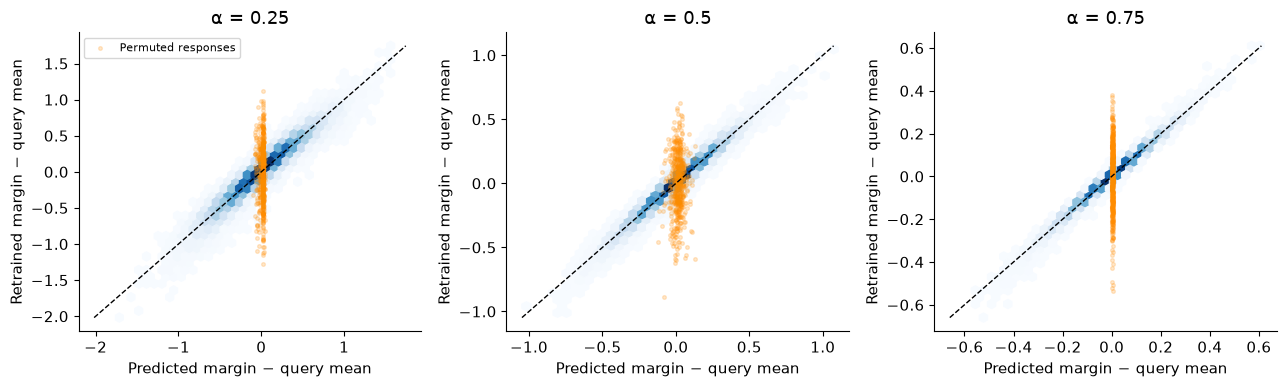

In [21]:
dm_evaluated = dm_evaluate_study(dm_prepared, dm_train, query, dm_methods, NATIVE)

dm_fig, dm_axes = dm_plt.subplots(1, 3, figsize=(13, 4))

for dm_ax, fraction in zip(dm_axes, FRACTIONS):
    result = dm_evaluated['test'][fraction]
    observed = result['margin']
    center = observed.mean(0)
    predicted = result['predictions']['lasso']
    xp, yp = ((predicted - center).flatten().numpy(), (observed - center).flatten().numpy())
    dm_ax.hexbin(xp, yp, gridsize=35, mincnt=1, cmap='Blues')
    control = (result['predictions']['permuted'] - center).flatten().numpy()
    dm_ax.scatter(control[::32], yp[::32], color='darkorange', alpha=0.2, s=7, label='Permuted responses')
    limits = [min(xp.min(), yp.min()), max(xp.max(), yp.max())]
    dm_ax.plot(limits, limits, 'k--', linewidth=1)
    dm_ax.set(xlabel='Predicted margin − query mean', ylabel='Retrained margin − query mean', title=f'α = {fraction}')

dm_axes[0].legend(fontsize=8)

dm_show_figure(dm_fig, 'datamodel_heldout_predictions')

The blue density follows the identity line; the permuted-response control mostly
predicts each query's average. But how well does this hold for the individual
queries? The next plot gives every query its own $R^2$:

$$R_x^2=1-\frac{\sum_r(\widehat f_{rx}-f_{rx})^2}{\sum_r(f_{rx}-\overline f_x)^2}.$$

An $R^2$ near one means we predict the subset-dependent variation. Zero is the
test-mean baseline and negative values are possible. Our actual intercept-only
model uses a training mean, so it need not land exactly at zero.

The worst query still has $R^2$ about 0.86, 0.94 and 0.98 as the subset fraction
increases. Least squares is very competitive, sometimes slightly better.
We retain that baseline instead of claiming that L1 regularization caused the
strong predictions.

Predict whether every query benefits equally from the surrogate; distinguish query averages from independent subset models.

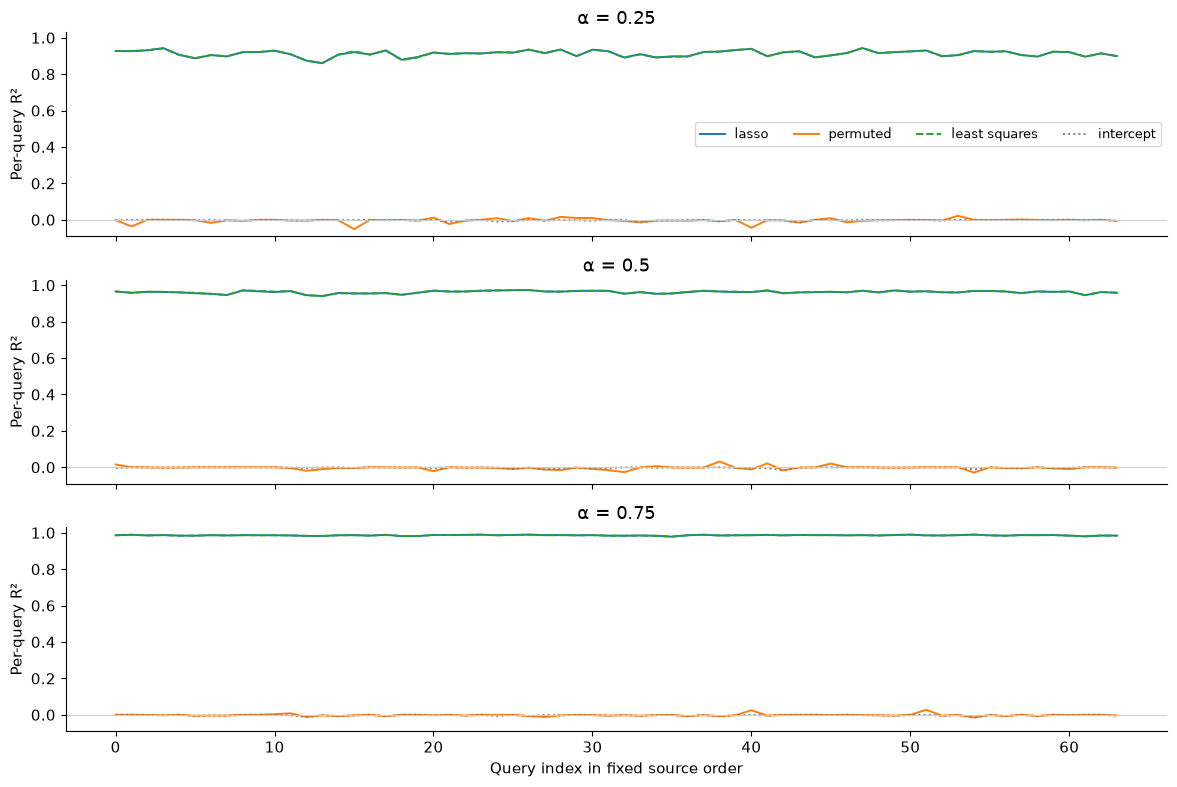

In [22]:
dm_fig, dm_axes = dm_plt.subplots(3, 1, figsize=(12, 8), sharex=True)

styles = {'lasso': ('C0', '-'), 'least_squares': ('C2', '--'), 'permuted': ('C1', '-'), 'intercept': ('0.5', ':')}

for dm_ax, fraction in zip(dm_axes, FRACTIONS):
    result = dm_evaluated['test'][fraction]
    observed = result['margin']
    for dm_name, prediction in result['predictions'].items():
        mse = (prediction - observed).square().mean(0)
        r2 = 1 - mse / observed.var(0, unbiased=False)
        color, linestyle = styles[dm_name]
        dm_ax.plot(r2, label=dm_name.replace('_', ' '), color=color, linestyle=linestyle, linewidth=1.4)
    dm_ax.set(ylabel='Per-query R²', title=f'α = {fraction}', ylim=(-0.09, 1.03))
    dm_ax.axhline(0, color='0.8', linewidth=0.7)

dm_axes[0].legend(ncol=4, fontsize=9)

dm_axes[-1].set_xlabel('Query index in fixed source order')

dm_show_figure(dm_fig, 'datamodel_query_r2')

### What did the extra training runs buy?

Keep the test set fixed and vary the number of subset/response pairs used for
regression. The left plot averages squared error over the same 64 queries and
256 held-out models. The right plot shows selected Lasso density. Comparing
against unpenalized least squares is particularly useful when the number of
observed training runs is comparable to the 128 coefficients.

Least-squares error spikes near 128 training models in this run. The third
panel diagnoses sensitivity: the condition number of the nonzero singular
values rises to about 218 there, compared with about 5.4 at 256 models.
The structural zero direction from fixed cardinality is excluded. This is
consistent with amplification of residuals that a linear surrogate cannot
fit; it is not evidence that the optimizer failed to solve least squares.

Forecast marginal error reduction as more fit subsets are supplied, keeping held-out subsets fixed.

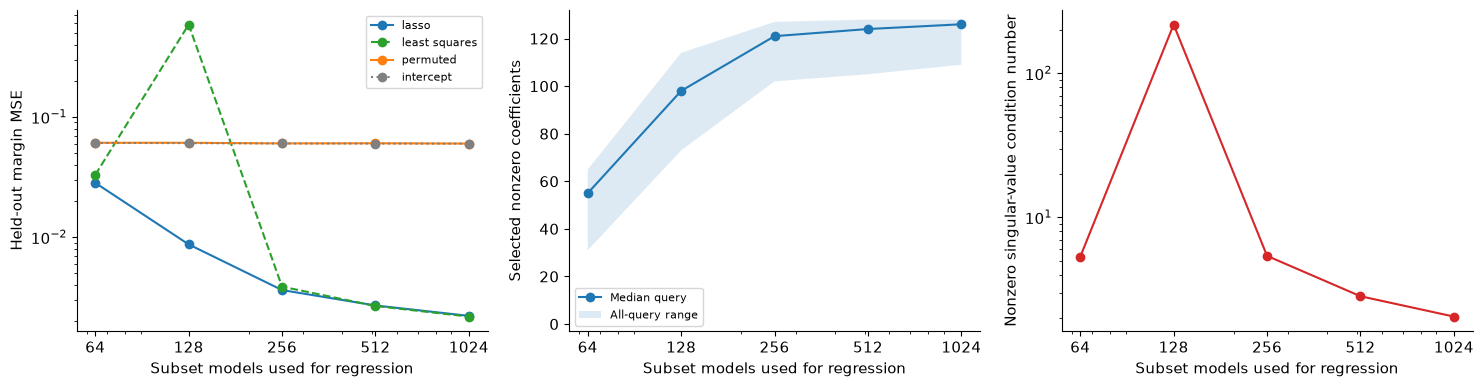

In [23]:
dm_counts = [64, 128, 256, 512, 1024]

observed = dm_evaluated['test'][0.5]['margin']

dm_fig, dm_axes = dm_plt.subplots(1, 3, figsize=(15, 4))

for dm_name, (color, linestyle) in styles.items():
    errors = []
    for count in dm_counts:
        predictions = dm_evaluated['test'][0.5]['predictions'] if count == 1024 else dm_evaluated['learning_predictions'][count]
        errors.append(float((predictions[dm_name] - observed).square().mean()))
    dm_axes[0].plot(dm_counts, errors, 'o', linestyle=linestyle, color=color, label=dm_name.replace('_', ' '))

densities = []

for count in dm_counts:
    response = dm_prepared['responses'][0.5] if count == 1024 else dm_prepared['learning'][count]
    densities.append((response['lasso']['selected_weights'] != 0).sum(0).double())

densities = dm_torch.stack(densities)

dm_axes[1].plot(dm_counts, densities.median(1).values, 'o-', label='Median query')

dm_axes[1].fill_between(dm_counts, densities.min(1).values, densities.max(1).values, alpha=0.15, label='All-query range')

dm_axes[0].set(xscale='log', yscale='log', xlabel='Subset models used for regression', ylabel='Held-out margin MSE')

dm_axes[1].set(xscale='log', xlabel='Subset models used for regression', ylabel='Selected nonzero coefficients', ylim=(-3, 132))

condition_numbers = []

design = dm_prepared['designs'][0.5]['train'].double()

for count in dm_counts:
    singular_values = dm_torch.linalg.svdvals(design[:count] - design[:count].mean(0))
    nonzero = singular_values[singular_values > 1e-10]
    condition_numbers.append(float(nonzero.max() / nonzero.min()))

dm_axes[2].plot(dm_counts, condition_numbers, 'o-', color='C3')

dm_axes[2].set(xscale='log', yscale='log', xlabel='Subset models used for regression', ylabel='Nonzero singular-value condition number')

for dm_ax in dm_axes:
    dm_ax.set_xticks(dm_counts, [str(c) for c in dm_counts])

for dm_ax in dm_axes[:2]:
    dm_ax.legend(fontsize=8)

dm_show_figure(dm_fig, 'datamodel_sample_complexity')

### Change the subset size

Apply every fitted datamodel to every test subset size. Diagonal cells use the
same sampling fraction for fitting and testing. Off-diagonal cells change the
distribution of training sets. The regressor receives the new membership mask,
but was never trained on that cardinality.

The difference is large: the datamodel fitted at $\alpha=0.25$ has MSE about
0.015 on its own test distribution and 0.344 on size-96 subsets. The coefficient
offset ambiguity explains why same-size success alone cannot establish a
unique extension to other sizes. Nonlinearity of the learning algorithm creates
another reason for the extension to fail.

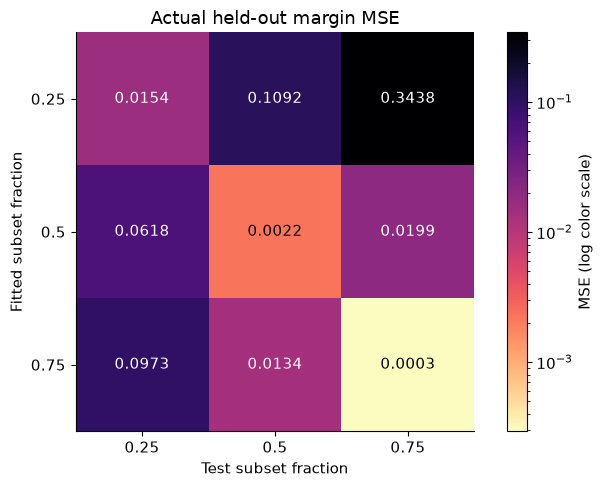

In [24]:
cross_mse = dm_torch.tensor([[float((dm_evaluated['cross_fraction'][target][source] - dm_evaluated['test'][target]['margin']).square().mean()) for target in FRACTIONS] for source in FRACTIONS])

dm_fig, dm_ax = dm_plt.subplots(figsize=(7, 5))

from matplotlib.colors import LogNorm

heat = dm_ax.imshow(cross_mse, cmap='magma_r', norm=LogNorm(vmin=float(cross_mse.min()), vmax=float(cross_mse.max())))

for dm_row in range(3):
    for dm_col in range(3):
        dm_ax.text(dm_col, dm_row, f'{cross_mse[dm_row, dm_col]:.4f}', ha='center', va='center', color='white' if cross_mse[dm_row, dm_col] > 0.01 else 'black')

dm_ax.set(xticks=range(3), xticklabels=FRACTIONS, yticks=range(3), yticklabels=FRACTIONS, xlabel='Test subset fraction', ylabel='Fitted subset fraction', title='Actual held-out margin MSE')

dm_fig.colorbar(heat, ax=dm_ax, label='MSE (log color scale)')

dm_show_figure(dm_fig, 'datamodel_cross_fraction')

## 9️⃣ Read coefficients as images, then confront them with retraining

The following gallery always uses the first two source-ordered queries of each
class. The datamodel fraction is 0.5. Compare its two largest and two smallest
coefficients with the two closest signed pixel neighbors. The score is relative
to the query's **correct-class margin**, not a universal value of the image.

Coefficients and pixel similarity can highlight different aspects of the same
task. A visually familiar image can be redundant; an opposing example can be
important because it constrains the decision boundary. The gallery suggests
hypotheses. The deletion experiment below tests them.

Forecast the coefficient sign for same-class and opposite-class images; explain a plausible counterexample.

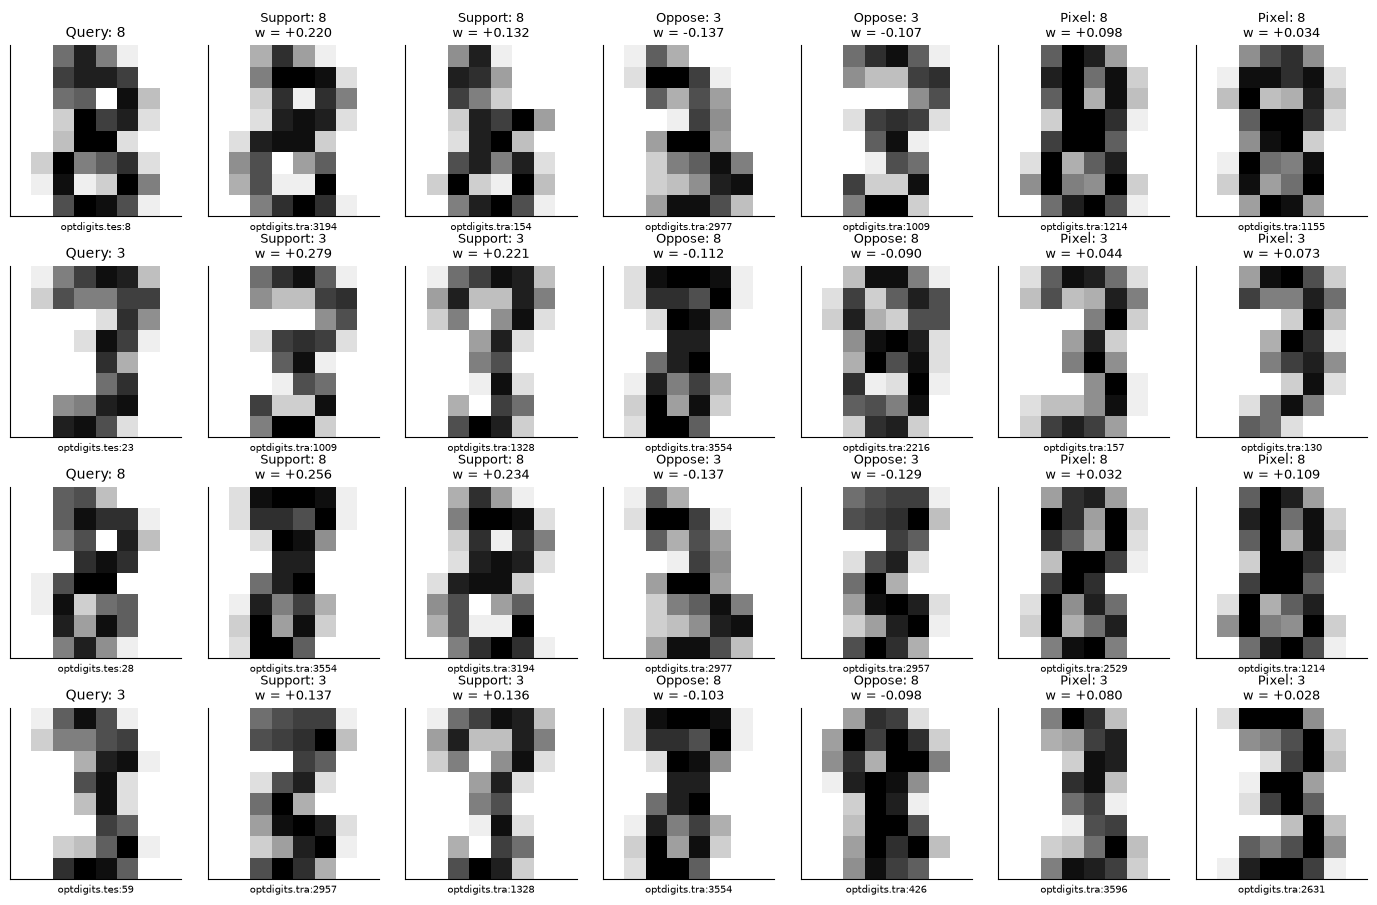

In [25]:
dm_gallery = dm_torch.cat([dm_torch.nonzero(query['y'] == label).flatten()[:2] for label in (0, 1)]).sort().values

weights = dm_prepared['responses'][0.5]['lasso']['selected_weights']

dm_fig, dm_axes = dm_plt.subplots(4, 7, figsize=(14, 9))

for dm_row, q in enumerate(dm_gallery.tolist()):
    w = weights[:, q]
    high = dm_torch.argsort(w, descending=True, stable=True)[:2]
    low = dm_torch.argsort(w, stable=True)[:2]
    close = dm_torch.argsort(dm_prepared['deletions']['pixel_scores'][:, q], descending=True, stable=True)[:2]
    dm_axes[dm_row, 0].imshow(query['images'][q], cmap='gray_r', vmin=0, vmax=1)
    dm_axes[dm_row, 0].set_title(f"Query: {query['digit'][q].item()}", fontsize=10)
    dm_axes[dm_row, 0].set_xlabel(query['ids'][q], fontsize=7)
    for dm_col, (dm_index, role) in enumerate(zip([*high, *low, *close], ['Support', 'Support', 'Oppose', 'Oppose', 'Pixel', 'Pixel']), start=1):
        dm_axes[dm_row, dm_col].imshow(dm_train['images'][dm_index], cmap='gray_r', vmin=0, vmax=1)
        dm_axes[dm_row, dm_col].set_title(f"{role}: {dm_train['digit'][dm_index].item()}\nw = {w[dm_index]:+.3f}", fontsize=9)
        dm_axes[dm_row, dm_col].set_xlabel(dm_train['ids'][dm_index], fontsize=7)

for dm_ax in dm_axes.flat:
    dm_ax.set_xticks([])
    dm_ax.set_yticks([])

dm_show_figure(dm_fig, 'datamodel_coefficient_gallery')

### Similarity between target-specific datamodels

Use your centered-weight cosine function to compare the queries' directions in
training-image space. For readability, the figure orders queries by their source
label; that display order changes no fit. The control independently shuffles
the training-image coordinates in each target's weight vector, preserving its
values while destroying correspondence between image identities.

This is an exploratory representation, not evidence of duplicate images or
train/test leakage. Those claims would require inspecting the images and
checking provenance, as we did for exact pixel duplicates at the start.

Predict how independent coefficient shuffles affect target-direction similarity.

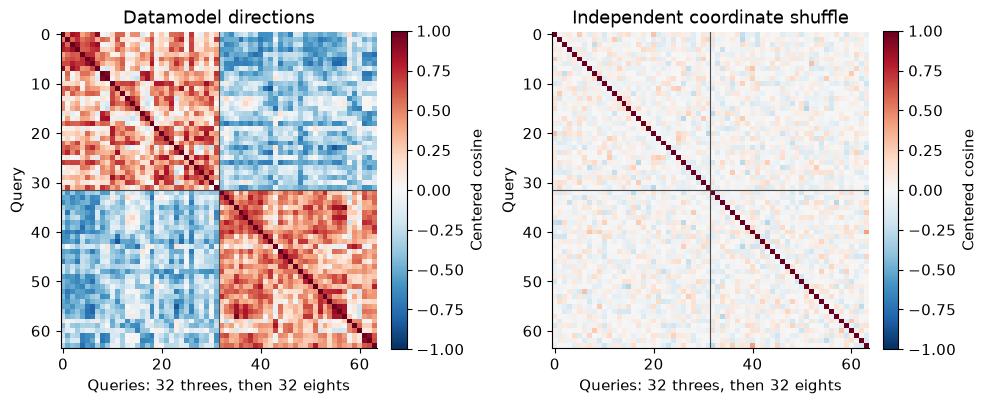

In [26]:
ordered = dm_torch.argsort(query['y'], stable=True)

weights = dm_prepared['responses'][0.5]['lasso']['selected_weights']

shuffled_weights = weights.clone()

generator = dm_torch.Generator().manual_seed(161771)

for q in range(weights.shape[1]):
    shuffled_weights[:, q] = weights[dm_torch.randperm(len(weights), generator=generator), q]

dm_fig, dm_axes = dm_plt.subplots(1, 2, figsize=(10, 4.5))

for dm_ax, current, dm_title in zip(dm_axes, [weights, shuffled_weights], ['Datamodel directions', 'Independent coordinate shuffle']):
    similarity = centered_weight_similarity(current)[ordered][:, ordered]
    heat = dm_ax.imshow(similarity, cmap='RdBu_r', vmin=-1, vmax=1)
    dm_ax.axvline(31.5, color='0.3', linewidth=0.8)
    dm_ax.axhline(31.5, color='0.3', linewidth=0.8)
    dm_ax.set(title=dm_title, xlabel='Queries: 32 threes, then 32 eights', ylabel='Query')
    dm_fig.colorbar(heat, ax=dm_ax, fraction=0.046, pad=0.04, label='Centered cosine')

dm_show_figure(dm_fig, 'datamodel_similarity')

### Did removing supportive images actually hurt the margin?

For each method and budget, the solid line is the mean observed margin change
across the 24 fixed queries. The dashed line is the datamodel prediction. The
gray band spans the sixteen matched-random replicate means; it is not a
confidence interval. The pixel baseline's predictions use the $\alpha=0.5$
datamodel for the images selected by pixel similarity.

All curves begin at zero for removing nothing. Negative means the correct-class
margin became smaller. The original full-pool classifier gets all 64 queries
right, so a later negative margin is an actual correct-to-incorrect transition.

Predict observed deletion-margin changes relative to class-matched random removal and pixel similarity; separate ranking from calibration.

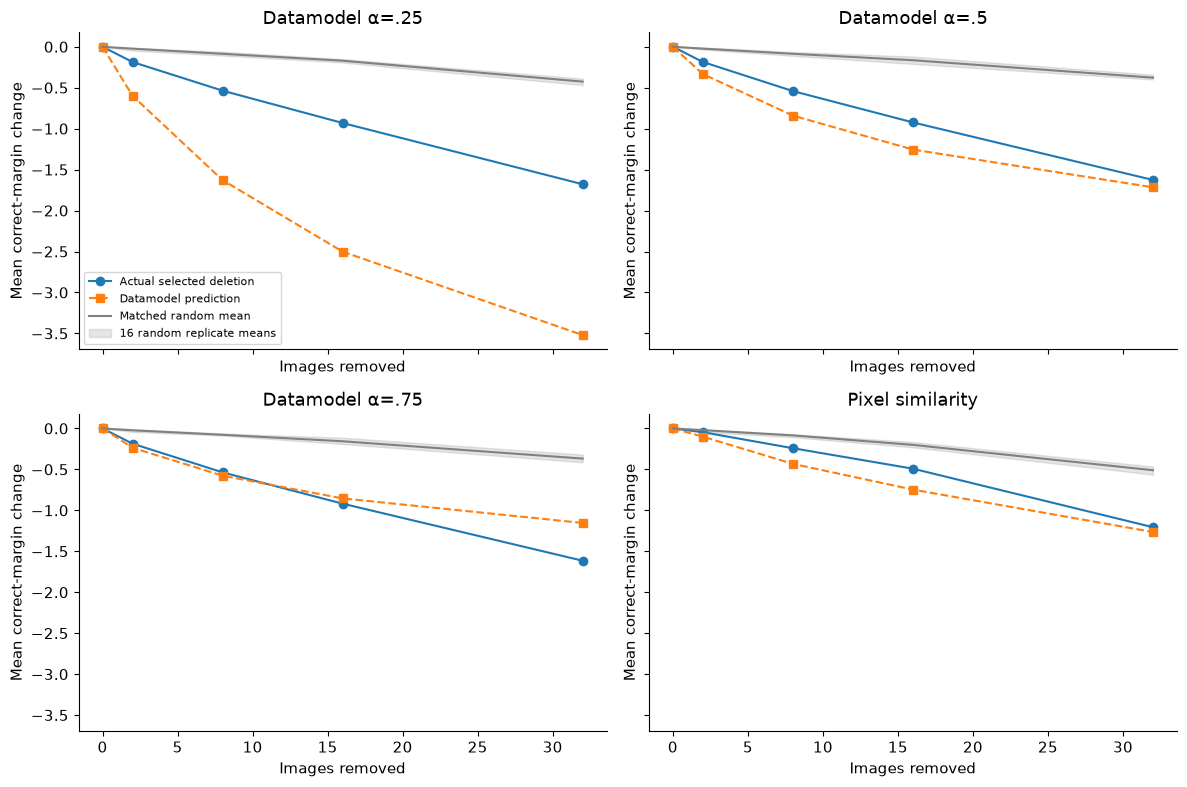

In [27]:
deletions = dm_prepared['deletions']

counterfactual = dm_evaluated['counterfactual']

method_labels = ['Datamodel α=.25', 'Datamodel α=.5', 'Datamodel α=.75', 'Pixel similarity']

dm_fig, dm_axes = dm_plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

for method_index, (dm_ax, dm_label) in enumerate(zip(dm_axes.flat, method_labels)):
    actual, prediction, low, high, average = ([0.0], [0.0], [0.0], [0.0], [0.0])
    for budget in BUDGETS:
        scope = (deletions['method'] == method_index) & (deletions['budget'] == budget)
        dm_chosen = scope & (deletions['replicate'] == -1)
        actual.append(float(counterfactual['actual_change'][dm_chosen].mean()))
        prediction.append(float(counterfactual['predicted_change'][dm_chosen, method_index if method_index < 3 else 1].mean()))
        controls = dm_torch.stack([counterfactual['actual_change'][scope & (deletions['replicate'] == rep)].mean() for rep in range(16)])
        low.append(float(controls.min()))
        high.append(float(controls.max()))
        average.append(float(controls.mean()))
    dm_budgets = [0, *BUDGETS]
    dm_ax.plot(dm_budgets, actual, 'o-', label='Actual selected deletion')
    dm_ax.plot(dm_budgets, prediction, 's--', label='Datamodel prediction')
    dm_ax.plot(dm_budgets, average, color='0.5', label='Matched random mean')
    dm_ax.fill_between(dm_budgets, low, high, color='0.5', alpha=0.2, label='16 random replicate means')
    dm_ax.set(title=dm_label, xlabel='Images removed', ylabel='Mean correct-margin change')

dm_axes[0, 0].legend(fontsize=8)

dm_show_figure(dm_fig, 'datamodel_deletion_curves')

The rankings find consequential images, but calibration depends strongly on the
fitted fraction. At budget 32 the $\alpha=0.25$ datamodel predicts a mean change
of about −3.52; actual retraining gives −1.68. For $\alpha=0.75$, the prediction
is −1.15 and the observed change is −1.62. Neither sign of error should be hidden.

At the same budget, the three datamodel rankings flip 4, 3 and 3 of the 24 fixed
queries; pixel similarity flips 3. A flipped query supplies a tested upper bound
on its minimum deletion support. We did not search all subsets, so this is not
an exact minimum, and it is not a theorem about unseen queries or models.

The next plot keeps all 24 query outcomes visible at the largest prescribed
budget. Some averaged effects conceal a much more fragile individual prediction.
The shaded flip-count control spans all four methods and sixteen random
replicates: no random cohort flips a query at budgets 2, 8 or 16, while
the budget-32 cohorts flip between zero and one of the 24 queries.

Forecast whether a large deletion preserves single-image additivity across subset fractions.

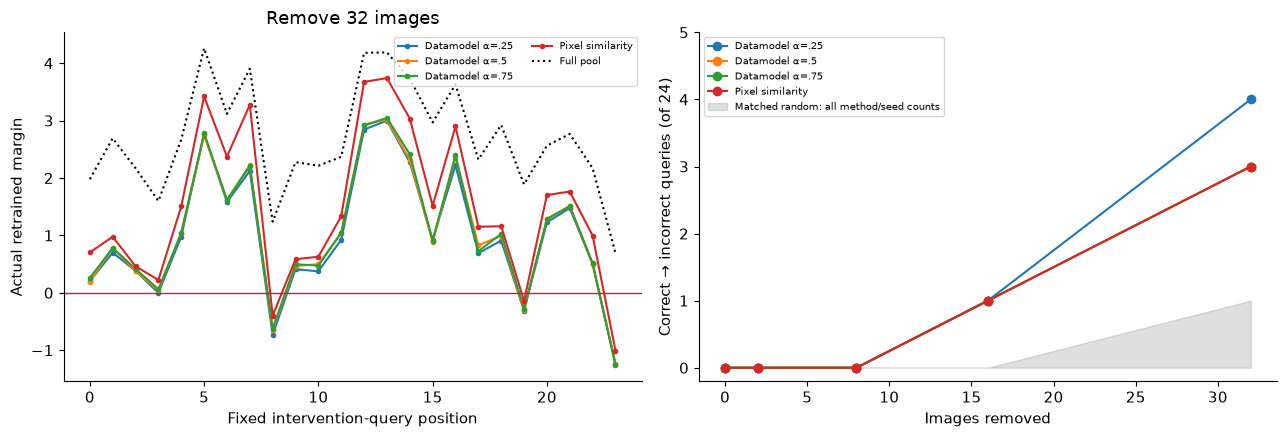

In [28]:
dm_fig, dm_axes = dm_plt.subplots(1, 2, figsize=(13, 4.5))

for method_index, dm_label in enumerate(method_labels):
    dm_chosen = (deletions['method'] == method_index) & (deletions['budget'] == 32) & (deletions['replicate'] == -1)
    targets = deletions['target'][dm_chosen]
    dm_axes[0].plot(range(len(targets)), counterfactual['target_margin'][dm_chosen], 'o-', markersize=3, label=dm_label)
    flips = []
    for budget in BUDGETS:
        dm_selected = (deletions['method'] == method_index) & (deletions['budget'] == budget) & (deletions['replicate'] == -1)
        flips.append(int((counterfactual['target_margin'][dm_selected] < 0).sum()))
    dm_axes[1].plot([0, *BUDGETS], [0, *flips], 'o-', label=dm_label)

dm_axes[0].plot(range(24), dm_evaluated['base_margin'][deletions['query_indices']], 'k:', label='Full pool')

dm_axes[0].axhline(0, color='crimson', linewidth=1)

dm_axes[0].set(xlabel='Fixed intervention-query position', ylabel='Actual retrained margin', title='Remove 32 images')

random_low, random_high = ([0], [0])

for budget in BUDGETS:
    dm_counts = []
    for method_index in range(4):
        for dm_replicate in range(16):
            dm_selected = (deletions['method'] == method_index) & (deletions['budget'] == budget) & (deletions['replicate'] == dm_replicate)
            dm_counts.append(int((counterfactual['target_margin'][dm_selected] < 0).sum()))
    random_low.append(min(dm_counts))
    random_high.append(max(dm_counts))

dm_axes[1].fill_between([0, *BUDGETS], random_low, random_high, color='0.5', alpha=0.25, label='Matched random: all method/seed counts')

dm_axes[1].legend(fontsize=7, loc='upper left')

dm_axes[1].set(xlabel='Images removed', ylabel='Correct → incorrect queries (of 24)', yticks=range(0, 6))

dm_axes[0].legend(fontsize=7, ncol=2)

dm_show_figure(dm_fig, 'datamodel_individual_flips')

### Try It Yourself — choose a query and retrain its counterfactual

Change `QUERY_INDEX`, `SUBSET_FRACTION` or `REMOVAL_BUDGET`. The function fits a
full-pool base model, your selected deletion and sixteen class-matched random
deletions from scratch. It shows a query image, the removed images and the
observed margin changes. The vertical line is the datamodel's predicted change.

Try a query whose margin stayed positive in the reference study, then one close
to the decision boundary. Compare the two fractions that over- and underpredicted
the average effect. These explorations are additional experiments; they do not
replace any point in the frozen reference study.

In [29]:
def deletion_play(prepared: dict, train: dict, query: dict, methods, query_index: int=0, fraction: float=0.5, budget: int=8) -> dict:
    """An editable intervention: base, selected deletion and sixteen random refits."""
    if not 0 <= query_index < len(query['y']) or fraction not in FRACTIONS:
        raise ValueError('Choose an available query and fitted subsampling fraction.')
    weights = prepared['responses'][fraction]['lasso']['selected_weights'][:, query_index]
    selected = methods.select_supportive(weights, budget)
    controls = methods.matched_random_removals(train['y'], selected, 16, 163001)
    removals = dm_torch.cat([selected[None], controls])
    masks = dm_torch.ones(18, len(train['y']), dtype=dm_torch.bool)
    for i, removed in enumerate(removals, start=1):
        masks[i, removed] = False
    fit = refit_masks(train, masks)
    margin = model_margins(fit, query, methods)[:, query_index]
    prediction = -(~masks).double() @ weights
    return dict(query_index=query_index, fraction=fraction, budget=budget, removals=removals, masks=masks, fit=fit, margin=margin, actual_change=margin - margin[0], predicted_change=prediction)

Choose the query and budget before seeing its retrained result; predict the selected-versus-random signed margin contrast.

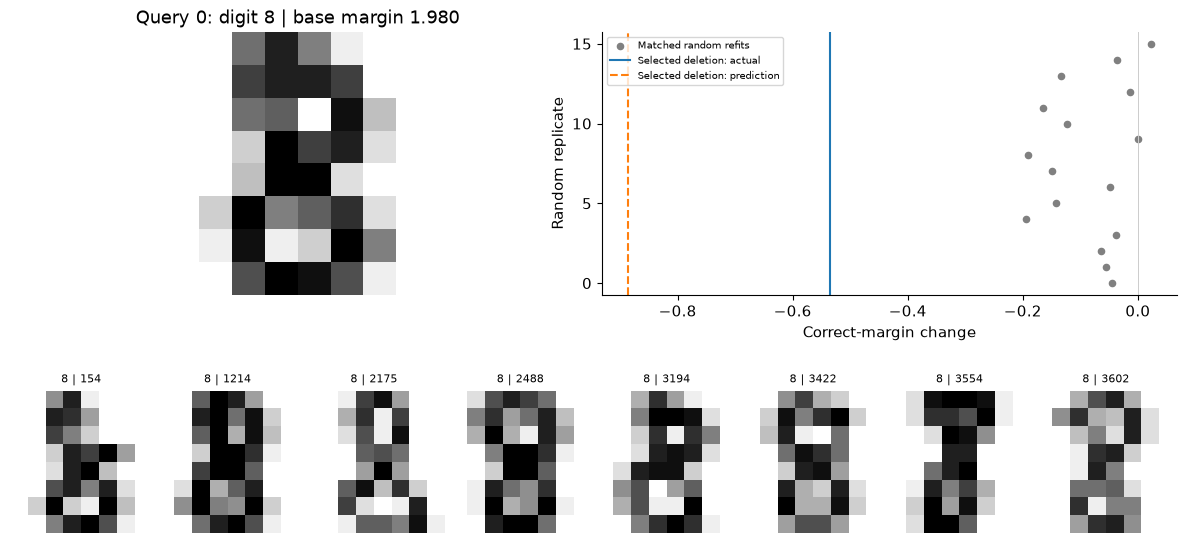

In [30]:
QUERY_INDEX = 0

SUBSET_FRACTION = 0.5

REMOVAL_BUDGET = 8

dm_play = deletion_play(dm_prepared, dm_train, query, dm_methods, QUERY_INDEX, SUBSET_FRACTION, REMOVAL_BUDGET)

dm_torch.save(dm_play, NATIVE / 'play.pt')

dm_fig = dm_plt.figure(figsize=(12, 6.5))

grid = dm_fig.add_gridspec(2, 2, height_ratios=[1, 1.25])

ax_query = dm_fig.add_subplot(grid[0, 0])

ax_query.imshow(query['images'][QUERY_INDEX], cmap='gray_r', vmin=0, vmax=1)

ax_query.set_title(f"Query {QUERY_INDEX}: digit {query['digit'][QUERY_INDEX].item()} | base margin {dm_play['margin'][0]:.3f}")

ax_query.axis('off')

ax_changes = dm_fig.add_subplot(grid[0, 1])

ax_changes.scatter(dm_play['actual_change'][2:], dm_np.arange(16), color='0.5', s=20, label='Matched random refits')

ax_changes.axvline(float(dm_play['actual_change'][1]), label='Selected deletion: actual', color='C0')

ax_changes.axvline(float(dm_play['predicted_change'][1]), label='Selected deletion: prediction', color='C1', linestyle='--')

ax_changes.axvline(0, color='0.8', linewidth=0.7)

ax_changes.set(xlabel='Correct-margin change', ylabel='Random replicate', yticks=[0, 5, 10, 15])

ax_changes.legend(fontsize=7)

removed = dm_play['removals'][0]

columns = min(8, max(1, len(removed)))

dm_rows = dm_math.ceil(max(1, len(removed)) / columns)

image_grid = grid[1, :].subgridspec(dm_rows, columns)

for dm_position in range(dm_rows * columns):
    dm_ax = dm_fig.add_subplot(image_grid[dm_position // columns, dm_position % columns])
    if dm_position < len(removed):
        dm_i = removed[dm_position]
        dm_ax.imshow(dm_train['images'][dm_i], cmap='gray_r', vmin=0, vmax=1)
        dm_ax.set_title(f"{dm_train['digit'][dm_i].item()} | {dm_train['ids'][dm_i].split(':')[-1]}", fontsize=8)
    dm_ax.axis('off')

dm_show_figure(dm_fig, 'datamodel_real_play')

## Interpreting the result

You have predicted a real classifier's output using only the identities of its
training images. Accurate held-out-subset prediction survives a per-query check,
and permuting the mask/response association destroys it. The training outputs,
not a report or precomputed explanation, supplied the supervision.

You also found an important boundary. Predictions learned at one subset size do
not automatically carry over to another. The same coefficient ranking can
identify damaging deletions while its predicted effect size is wrong. Actual
retraining, class-matched controls and the offset derivation let you distinguish
these claims.

## Limitations and further investigations

- The base learner is a small deterministic convex classifier. The paper studies
  stochastic deep networks and expected outputs across training randomness.
  This lesson does not reproduce that noise floor, architecture or data scale.
- The 64 query images are held out from classifier fitting. They are deliberately
  present as datamodel targets; the 256 test **subsets** per fraction are the
  unseen inputs used for our central predictive evaluation.
- Most selected coefficient vectors are dense. Lasso and least squares are
  close here, and many validation choices hit the weakest tested penalty.
- Deletion rankings and their controls test particular subsets. An observed flip
  bounds the minimum support from above; it does not find a globally minimal set.
- Coefficient similarity is exploratory. It does not establish duplicate data,
  semantic equivalence, universal example value or an exact Shapley allocation.

For anomaly hunting, start with the worst per-query held-out prediction. Inspect
its image and the masks with large errors. Then compare two deletion sets with
similar predicted changes and different actual outcomes. Is class composition
enough to explain the difference? What additional interaction would a linear
datamodel need to represent it?

## Reading

- [Ilyas et al. (2022), Datamodels: Understanding Predictions with Data and Data with Predictions](https://proceedings.mlr.press/v162/ilyas22a.html).
  Sections 1–3 give the framework, fixed-size sampling and sparse regression;
  section 4 tests data counterfactuals. The linked PDF retains an earlier title.
- [The authors' Datamodels implementation](https://github.com/MadryLab/datamodels).
  Its separation between subset training and regression is useful when scaling
  beyond the CPU-sized experiment here.
- [16.9 Influence Functions and TracIn](../part9_influence_and_tracin/README.md).
  Compare the estimands: local upweight derivatives, checkpoint gradient
  agreement, and a learned predictor of complete subset retraining outcomes.

In [31]:
from chapter16_shapley_attribution_baselines.exercises.part10_datamodels.run_native import reference_checks as dm_reference_checks

references = dm_reference_checks(data, dm_prepared, dm_evaluated)

gradient_values = [fit['gradient_norm'].max() for values in dm_prepared['subset_fits'].values() for fit in values.values()]

gradient_values += [value['fit']['gradient_norm'].max() for value in dm_evaluated['test'].values()]

gradient_values += [dm_evaluated['base_fit']['gradient_norm'].max(), counterfactual['fit']['gradient_norm'].max()]

dm_summary = {'native_directory': str(NATIVE), 'classifier_refits': 10753, 'separate_refits': 6, 'independent_scipy_optima': 10, 'independent_lasso_fits': 12, 'play_refits': 18, 'train_images': 128, 'query_images': 64, 'heldout_subsets_per_fraction': 256, 'selection_used_test_responses': False, 'max_classifier_gradient': float(dm_torch.stack(gradient_values).max()), 'base_query_correct': int((dm_evaluated['base_margin'] > 0).sum())}

(dm_OUTPUT / 'native_summary.json').write_text(dm_json.dumps(dm_summary, indent=2) + '\n')

(dm_OUTPUT / 'reference_checks.json').write_text(dm_json.dumps(references, indent=2) + '\n')

print('Independent classifier and Lasso checks passed. All native fits and figures are saved.')

Independent classifier and Lasso checks passed. All native fits and figures are saved.


## Summary of 1️⃣

State the scientific intervention, selection boundary, negative controls and evaluation unit before comparing this study with the other track.

# 2️⃣ Dataset Cartography: read training histories

## [16.11] Dataset Cartography

## Introduction

**Can a model's learning history tell you which training examples to keep?**

Suppose two handwritten digits both receive the correct answer after training.
One was recognized almost immediately. The other spent ten epochs looking like
a different digit before the model learned it. Final accuracy treats them alike.
A **data map** puts their learning histories back into the picture.

In these exercises you will make this map yourself, follow particular images
across training, and use the map to choose training data. Then you will train
fresh models to find out whether your choices helped. You will also inject a
known set of label errors and investigate how reliably the map finds them.

### Original study goals

1. **Coordinates from learning histories.** Track stable example IDs, compute
   assigned-label confidence, temporal variability and correctness, and derive
   the curved boundary of a data map.
2. **Map a real training run.** Implement the logging loop; compare seeds,
   architectures, logging times, label errors and training windows. Inspect the
   images behind the points instead of treating region names as ground truth.
3. **Choose data, then retrain.** Compare map regions with uniform and
   class-matched random subsets; separate data-selection effects from class
   coverage and optimizer-update budgets.

You should be comfortable with minibatch training and PyTorch autograd from
original ARENA [0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
[16.9 Influence and TracIn](../part9_influence_and_tracin/README.md) and
[16.10 Datamodels](../part10_datamodels/README.md) ask related questions about
training data. Here we begin with the history of one training run rather than
an optimum derivative or a regression across many subsets.

Allow **4–6 hours** for the implementations, explanations and experiments.
The complete reference experiment runs on CPU. Its speed comes from training
small independent networks together, with no shared parameters or cached fits.
The first run downloads a small public dataset; subsequent runs check the same
source bytes locally.

## Setup

In [32]:
from pathlib import Path as cart_Path

from types import SimpleNamespace as cart_SimpleNamespace

import hashlib as cart_hashlib

import json as cart_json

import math as cart_math

import os as cart_os

import sys as cart_sys

import tempfile as cart_tempfile

import numpy as cart_np

import torch as cart_torch

from torch import Tensor as cart_Tensor

import torch.nn.functional as F

import matplotlib.pyplot as cart_plt

from IPython import get_ipython as cart_get_ipython

if cart_get_ipython() is not None:
    cart_get_ipython().run_line_magic('matplotlib', 'inline')

cart_ROOT = next((p for p in [cart_Path.cwd(), *cart_Path.cwd().parents] if (p / 'chapter16_shapley_attribution_baselines').exists()))

if str(cart_ROOT) not in cart_sys.path:
    cart_sys.path.insert(0, str(cart_ROOT))

from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography import cartography_methods_tests as cart_tests

from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography.cartography_data import load_training, load_evaluation

from chapter16_shapley_attribution_baselines.exercises.part11_dataset_cartography.run_native import validate_freeze, reference_checks as cart_reference_checks, summarize

cart_torch.set_num_threads(4)

cart_torch.use_deterministic_algorithms(True)

cart_OUTPUT = cart_Path(cart_os.environ.get('ARENA_CARTOGRAPHY_OUTPUT_DIRECTORY', '/tmp/arena16_11_cartography'))

cart_OUTPUT.mkdir(parents=True, exist_ok=True)

cart_plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

def cart_show_figure(figure, name):
    figure.savefig(cart_OUTPUT / f'{name}.png', dpi=145, bbox_inches='tight')
    cart_plt.show()
    cart_plt.close(figure)

validate_freeze()

cart_train = load_training()

print(f"Training pool: {len(cart_train['ids'])} images; 300 per digit; 300 known injected label errors.")

Training pool: 3000 images; 300 per digit; 300 known injected label errors.


### A label is an assertion you can inspect

The source contains 8×8 images of ten handwritten digits. We use 3,000 images
from the original training file, chosen before fitting any model. The remaining
823 images form a same-source holdout. The original 1,797-image test file comes
from separate writers. No exact pixel duplicates cross either training/holdout
boundary. Individual writer IDs are unavailable, so the same-source holdout is
not guaranteed to contain different writers.

For the noise experiment, we change exactly 30 labels per class to the next
class modulo ten. The original images stay fixed. This is deliberately created
noise, with a known answer to the diagnosis exercise. It does not establish that
an untouched source example has an annotation error.

Look at the images below. For each changed label, predict what will happen to
the probability of its **assigned** label during training.

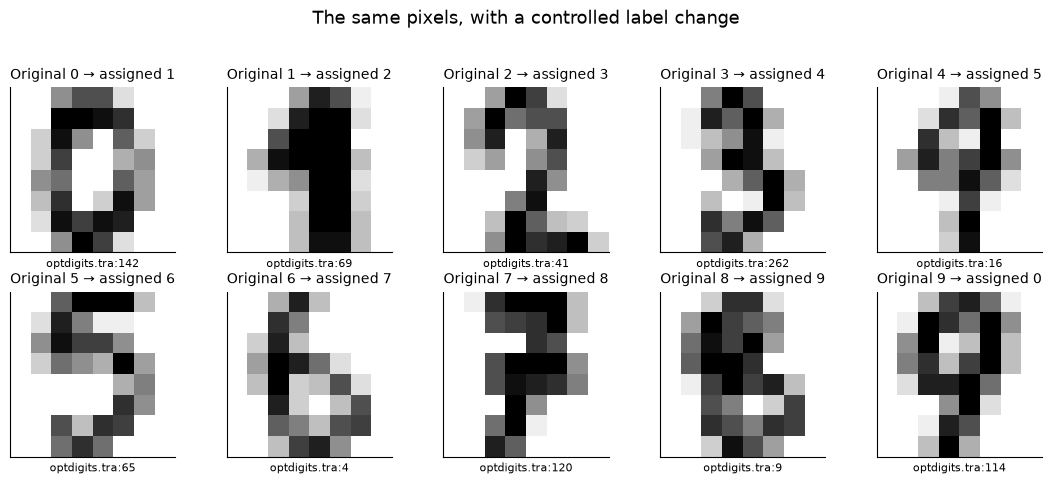

In [33]:
cart_fig, cart_axes = cart_plt.subplots(2, 5, figsize=(11, 4.6))

for cart_position, cart_ax in enumerate(cart_axes.flat):
    indices = cart_torch.where((cart_train['y'] == cart_position) & cart_train['changed'])[0]
    cart_index = int(indices[0])
    cart_ax.imshow(cart_train['x'][cart_index].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    cart_ax.set_title(f"Original {cart_position} → assigned {int(cart_train['noisy_y'][cart_index])}", fontsize=10)
    cart_ax.set_xlabel(cart_train['ids'][cart_index], fontsize=8)
    cart_ax.set_xticks([])
    cart_ax.set_yticks([])

cart_fig.suptitle('The same pixels, with a controlled label change', y=1.03)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_images')

## 1️⃣ Turn a learning history into coordinates

For example $i$, let $p_{e,i}$ be the probability assigned to its dataset label
at epoch $e$. The label may be wrong. This is **not** the maximum probability
among classes. A network that confidently calls a mislabeled “3” an “8” can
have a high maximum probability and a very low assigned-label probability.

Our three coordinates are

$$\mu_i=\frac{1}{E}\sum_{e=1}^E p_{e,i},\qquad
\sigma_i=\sqrt{\frac{1}{E}\sum_{e=1}^E(p_{e,i}-\mu_i)^2},\qquad
c_i=\frac{1}{E}\sum_{e=1}^E\mathbf{1}[\arg\max_k z_{e,i,k}=y_i].$$

Confidence is $\mu$, variability is $\sigma$, and correctness is $c$. The data
map places variability horizontally and confidence vertically; color represents
correctness. These summaries discard temporal order. A steadily improving
example can have the same coordinates as an example that repeatedly flips.

Before computing them, we need to make sure that row 17 at one epoch still
means the same image at the next epoch. Minibatch shuffling makes this easy to
get wrong without producing an obvious tensor-shape error.

### Exercise - restore example identity after shuffling

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`logits` has shape `[models, examples, classes]`. Each corresponding row of
`visited_ids` is a permutation of canonical IDs `0, ..., N-1`. Return logits in
canonical order. Reject duplicates, missing IDs and shape mismatches. Different
models may visit examples in different orders.

Predict how permuting visitation order affects raw versus ID-aligned histories.

In [34]:
def align_epoch(logits: cart_Tensor, visited_ids: cart_Tensor) -> cart_Tensor:
    """Restore B × N × C logits to canonical integer IDs 0 through N-1."""
    if logits.ndim != 3 or visited_ids.shape != logits.shape[:2]:
        raise ValueError('Expected one visited ID per model and example.')
    expected = cart_torch.arange(logits.shape[1], device=visited_ids.device)
    if not cart_torch.equal(visited_ids.sort(dim=1).values, expected.expand_as(visited_ids)):
        raise ValueError('Every epoch must visit each ID exactly once; check missing/duplicate IDs.')
    return logits.gather(1, visited_ids.argsort(dim=1)[..., None].expand_as(logits))

cart_tests.test_align_epoch(align_epoch)

align_epoch passed: source IDs survive shuffling; duplicate and missing visits fail.


<details>
<summary>Help - where should I start?</summary>

Sort the IDs, check that the sorted values equal `arange(N)`, then use the
sorting indices to gather the class vectors. Sorting the logits themselves
would destroy the labels' meaning.

</details>

<details>
<summary>Expected output</summary>

The shuffled example with canonical ID 2 returns to row 2 for both models.
Duplicate or missing visits raise an informative error. A passing shape check
alone would not catch the identity bug.

</details>

### Exercise - compute confidence, variability and correctness

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement the assigned-label probability and the three map statistics.
The full logit tensor has shape `[epochs, models, examples, classes]`; labels
have shape `[models, examples]`. Preserve model and example axes. Use population
standard deviation and the first class index for an argmax tie.

In [35]:
def gold_probabilities(logits: cart_Tensor, labels: cart_Tensor) -> cart_Tensor:
    """Gather the assigned label, preserving any leading epoch dimension."""
    probabilities = logits.softmax(dim=-1)
    indices = labels.expand(logits.shape[:-1]).unsqueeze(-1)
    return probabilities.gather(-1, indices).squeeze(-1)

cart_tests.test_gold_probabilities(gold_probabilities)


def training_statistics(logits: cart_Tensor, labels: cart_Tensor) -> dict[str, cart_Tensor]:
    """Reduce E × B × N × C over epochs only; variability uses population SD."""
    if logits.ndim != 4 or logits.shape[0] == 0 or labels.shape != logits.shape[1:3]:
        raise ValueError('Use nonempty epoch/model/example/class logits and model/example labels.')
    probabilities = gold_probabilities(logits, labels)
    return dict(confidence=probabilities.mean(dim=0), variability=probabilities.std(dim=0, correction=0), correctness=(logits.argmax(dim=-1) == labels).float().mean(dim=0))

cart_tests.test_training_statistics(training_statistics)

gold_probabilities passed: assigned labels and stable softmax, including wrong predictions.
training_statistics passed: epoch axis, population SD, correctness fraction and ties.


<details>
<summary>Help - where should I start?</summary>

Apply softmax over the last axis, gather labels, then reduce over axis zero.
PyTorch's default standard-deviation correction is one; the paper divides by
`E`, so use `correction=0`. A one-epoch map must have variability zero.

</details>

<details>
<summary>Expected output</summary>

The history `[0.1, 0.5, 0.9]` has confidence 0.5 and variability about 0.327.
A constant history has zero variability. The tests distinguish assigned-label
probability from top-class probability and check ties and a one-epoch window.

</details>

### Why does the map have a curved edge?

For any $p\in[0,1]$, $p^2\le p$. Apply this inequality to every epoch and take
the mean. What upper bound does it give on $\sigma^2$? What kinds of learning
histories approach the boundary?

<details><summary>Help - expand the variance</summary>

Write $\sigma^2=E[p^2]-E[p]^2$. Here $E[\cdot]$ is an average over the recorded
epochs, not an expectation over independently trained models.

</details>

<details><summary>Solution - variance bound</summary>

$$\sigma^2\le\mu-\mu^2=\mu(1-\mu).$$

Equality requires probabilities to be zero or one at every recorded epoch.
The boundary is therefore a mathematical property of bounded probabilities;
it is not evidence for three natural species of training examples. In particular,
large variability requires confidence away from both zero and one.

</details>

### Try It Yourself - change a learning history

Change `history` below. Try a smooth rise, alternating extremes, and a constant
sequence. Predict the point before running the cell. Then reverse or permute
exactly the same values: the map point stays fixed even though the story changes.
The dashed constant history is the control. These are probability fixtures,
not outputs from the digit classifier.

Predict the largest possible variability at fixed mean and a history that approaches it.

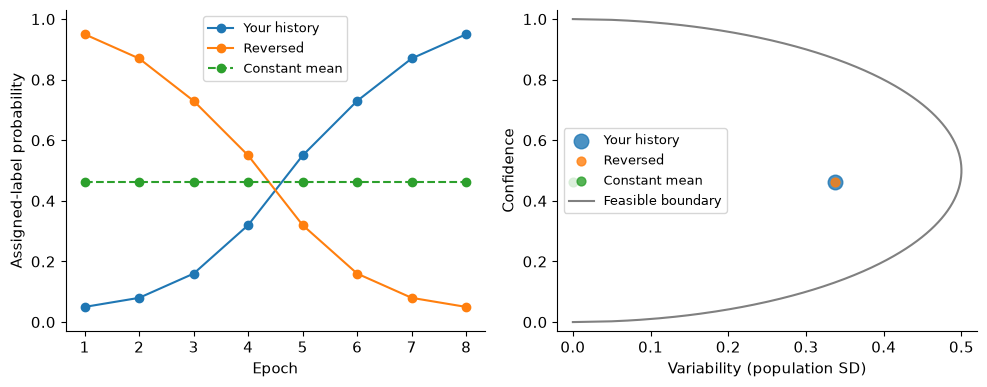

In [36]:
history = cart_torch.tensor([0.05, 0.08, 0.16, 0.32, 0.55, 0.73, 0.87, 0.95])

assert ((history > 0) & (history < 1)).all(), 'Keep fixture probabilities strictly between zero and one.'

curves = {'Your history': history, 'Reversed': history.flip(0), 'Constant mean': history.mean().expand_as(history)}

cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(10, 4))

for cart_name, cart_values in curves.items():
    logits = cart_torch.stack([cart_values.log(), (1 - cart_values).log()], dim=-1)[:, None, None]
    point = training_statistics(logits, cart_torch.zeros(1, 1, dtype=cart_torch.long))
    cart_axes[0].plot(range(1, len(cart_values) + 1), cart_values, 'o--' if cart_name == 'Constant mean' else 'o-', label=cart_name)
    cart_axes[1].scatter(point['variability'], point['confidence'], s=110 if cart_name == 'Your history' else 40, label=cart_name, alpha=0.8)

mu = cart_torch.linspace(0, 1, 401)

cart_axes[1].plot(cart_torch.sqrt(mu * (1 - mu)), mu, color='gray', label='Feasible boundary')

cart_axes[0].set(xlabel='Epoch', ylabel='Assigned-label probability', ylim=(-0.03, 1.03))

cart_axes[1].set(xlabel='Variability (population SD)', ylabel='Confidence', xlim=(-0.02, 0.52), ylim=(-0.03, 1.03))

for cart_ax in cart_axes:
    cart_ax.legend(fontsize=9)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_trajectory_play')

## 2️⃣ Make the map from actual training

We will train a 64 → 64 → 10 ReLU network with ordinary minibatch SGD. Each
independent run has its own parameters, random generator, initialization and
epoch permutation. The extra leading dimension below simply schedules several
runs together. There is no ensembling of predictions during training.

The optimizer uses learning rate 0.05, momentum 0.9 and weight decay 0.0001 on
all parameters, including biases. We train for 30 epochs with batches of 128,
including the final partial batch. There is no dropout, augmentation, early
stopping, tuned checkpoint or learned input normalization.

The initialization helper below provides the small architecture's parameters.
The two central operations—forward computation and training/logging—are yours
to implement. A width of zero selects the linear comparison model.

In [37]:
def initialize_parameters(features, classes, width, generators):
    """Small architecture setup; independent generators also supply batch orders."""
    draws = []
    for generator in generators:
        if width:
            item = dict(w1=cart_torch.randn(features, width, generator=generator) * cart_math.sqrt(2 / features), b1=cart_torch.zeros(1, width), w2=cart_torch.randn(width, classes, generator=generator) / cart_math.sqrt(width), b2=cart_torch.zeros(1, classes))
        else:
            item = dict(w=cart_torch.randn(features, classes, generator=generator) / cart_math.sqrt(features), b=cart_torch.zeros(1, classes))
        draws.append(item)
    return {name: cart_torch.stack([item[name] for item in draws]).requires_grad_() for name in draws[0]}

### Exercise - evaluate independent networks together

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Apply each parameter set to its corresponding input tensor. Inputs have shape
`[B, N, D]`, hidden weights `[B, D, H]`, hidden biases `[B, 1, H]`, output weights
`[B, H, C]`, and output biases `[B, 1, C]`. The linear case has keys `w` and `b`.
Return `[B, N, C]` logits. Keep the model axis intact.

Predict whether changing one ensemble member changes another member logits.

In [38]:
def batched_logits(parameters: dict[str, cart_Tensor], x: cart_Tensor) -> cart_Tensor:
    """Apply independent linear or one-hidden-layer networks along model axis B."""
    if 'w1' in parameters:
        hidden = (x @ parameters['w1'] + parameters['b1']).relu()
        return hidden @ parameters['w2'] + parameters['b2']
    return x @ parameters['w'] + parameters['b']

cart_tests.test_batched_logits(batched_logits)

batched_logits passed: independent linear and nonlinear networks match NumPy.


<details>
<summary>Help - where should I start?</summary>

Matrix multiplication handles the leading model dimension. ReLU belongs
between the two linear operations. A model's output must not depend on another
model's weights or examples.

</details>

<details>
<summary>Expected output</summary>

Both architectures agree with an independent NumPy loop for each model.
No averaging over models occurs.

</details>

### Two reasonable logging times can yield different maps

The paper's equation uses the parameters at the **end of an epoch**. The released
training loop instead saves an example's logits when its minibatch is visited,
before that minibatch's update. The two records answer different questions:

- **Visited minibatch:** how did the model respond when it trained on this example?
- **Epoch end:** how does one common checkpoint respond to every example?

We retain both. The main results use epoch-end snapshots; we directly measure
how much the other convention changes the map. This distinction matters most
when substantial learning happens during the first epoch.

A common bug in accelerated training is to take a mean over models as well as
examples. That divides each network's gradient by the number of scheduled runs.
Use the mean loss **within each model**, then sum those independent losses before
calling autograd. The sum introduces no cross-model gradient paths.

### Exercise - train and record both learning histories

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 35-45 minutes on this exercise.
> ```

Train fresh models and return final parameters, both `[E, B, N, C]` logit
traces, `[E, B]` epoch-end losses, seed metadata and the number of updates per
model. Reuse the initializer and forward function above. Each epoch must visit
every training example exactly once. Record visited logits before updating,
then realign them by canonical ID. Record the second trace after the full epoch.
For `record=False`, retain final parameters and epoch losses but return empty
logit traces; this saves memory for the later pruning experiments.

Predict how online pre-update logits differ from full epoch-end logits even with identical seeds.

In [39]:
def train_ensemble(x: cart_Tensor, labels: cart_Tensor, seeds: list[int], width: int=64, epochs: int=30, batch_size: int=128, lr: float=0.05, momentum: float=0.9, weight_decay: float=0.0001, classes: int=10, record: bool=True) -> dict:
    """Fresh SGD runs, with pre-update visits and epoch-end snapshots aligned by ID."""
    if x.ndim != 3 or labels.shape != x.shape[:2] or len(seeds) != x.shape[0]:
        raise ValueError('Provide B × N × D inputs, B × N labels and B run seeds.')
    if min(epochs, batch_size, x.shape[1]) < 1:
        raise ValueError('Epoch, minibatch and dataset sizes must be positive.')
    generators = [cart_torch.Generator().manual_seed(seed) for seed in seeds]
    parameters = initialize_parameters(x.shape[-1], classes, width, generators)
    velocity = {name: cart_torch.zeros_like(value) for name, value in parameters.items()}
    model_ids = cart_torch.arange(len(seeds))[:, None]
    online_trace, end_trace, losses = ([], [], [])
    steps = 0
    for _ in range(epochs):
        order = cart_torch.stack([cart_torch.randperm(x.shape[1], generator=g) for g in generators])
        visits = []
        for start in range(0, x.shape[1], batch_size):
            ids = order[:, start:start + batch_size]
            batch_x, batch_y = (x[model_ids, ids], labels[model_ids, ids])
            logits = batched_logits(parameters, batch_x)
            if record:
                visits.append(logits.detach().clone())
            individual_losses = F.cross_entropy(logits.flatten(0, 1), batch_y.flatten(), reduction='none').reshape_as(batch_y).mean(dim=1)
            gradients = cart_torch.autograd.grad(individual_losses.sum(), tuple(parameters.values()))
            with cart_torch.no_grad():
                for (name, value), gradient in zip(parameters.items(), gradients):
                    gradient = gradient + weight_decay * value
                    velocity[name].mul_(momentum).add_(gradient)
                    value.add_(velocity[name], alpha=-lr)
            steps += 1
        with cart_torch.no_grad():
            end = batched_logits(parameters, x)
            losses.append(F.cross_entropy(end.flatten(0, 1), labels.flatten(), reduction='none').reshape_as(labels).mean(dim=1))
            if record:
                online_trace.append(align_epoch(cart_torch.cat(visits, dim=1), order))
                end_trace.append(end.clone())
    return dict(parameters={name: value.detach().clone() for name, value in parameters.items()}, online_logits=cart_torch.stack(online_trace) if record else cart_torch.empty(0), end_logits=cart_torch.stack(end_trace) if record else cart_torch.empty(0), loss=cart_torch.stack(losses), steps=steps, seeds=list(seeds), width=width, n=x.shape[1])

cart_tests.test_train_ensemble(train_ensemble)

train_ensemble passed: ordinary torch.nn/SGD oracle checks both seeds, architectures, snapshots and gradients.


<details>
<summary>Help - where should I start?</summary>

Create one generator per run and draw its weights before its permutations.
For momentum, the first buffer is the gradient including weight decay; a zero
buffer followed by `buffer = momentum * buffer + gradient` gives this behavior.
Update parameters under `torch.no_grad()`. Clone recorded tensors so later
updates cannot alter earlier observations. Check the final partial minibatch.

</details>

<details>
<summary>Expected output</summary>

An independent ordinary `torch.nn` + `torch.optim.SGD` loop matches both
architectures and both seeds on a small fixture, including every visited logit,
epoch-end logit, final parameter and loss. The fixture has nine updates, not six.
The two logging conventions produce different traces.

</details>

### Region names become selection rules

“Easy,” “hard,” and “ambiguous” are descriptions relative to this model and
training history. For the experiments, we make them operational: highest mean
assigned-label probability, lowest mean assigned-label probability, and highest
variability. They are overlapping rankings; they do not partition the dataset.
The number retained is an explicit budget, not a universal region boundary.

### Exercise - rank a region with stable ties

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the top `k` canonical example indices. `largest=False` returns the
lowest scores. Ties must preserve source order so later selections are repeatable.
Validate finite scores and a legal retained size.

Predict which source index wins a tied score; explain why hard/easy/ambiguous rankings need not partition the dataset.

In [40]:
def select_indices(score: cart_Tensor, k: int, largest: bool=True) -> cart_Tensor:
    """Rank examples; ties retain canonical source order."""
    if score.ndim != 1 or not 0 < k <= score.numel() or (not cart_torch.isfinite(score).all()):
        raise ValueError('Use a finite score vector and a positive retained size at most N.')
    return cart_torch.argsort(score, descending=largest, stable=True)[:k]

cart_tests.test_select_indices(select_indices)

select_indices passed: direction, retained size and stable ties.


<details>
<summary>Help - where should I start?</summary>

Use a stable argsort. Do not sort by label or silently choose a threshold that
changes the requested number of retained examples.

</details>

<details>
<summary>Expected output</summary>

For scores `[0.2, 0.7, 0.7, -0.1]`, the top three indices are `[1, 2, 0]`.
The lowest two are `[3, 0]`.

</details>

### Exercise - measure retrieval of known label errors

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Treat low confidence as an inspection ranking. At each requested budget,
return the number of known injected errors found, precision and recall. Preserve
the input order of budgets. Use the provided boolean error mask only for scoring
the ranking, never for choosing its order.

Predict noise-retrieval precision at random selection and distinguish it from recall.

In [41]:
def retrieval_curve(score: cart_Tensor, changed: cart_Tensor, budgets: cart_Tensor) -> dict[str, cart_Tensor]:
    """Low-confidence retrieval of known injected errors, with stable ranking ties."""
    if changed.shape != score.shape or not changed.any() or changed.dtype != cart_torch.bool:
        raise ValueError('Provide an aligned boolean error mask containing at least one error.')
    if budgets.ndim != 1 or not ((budgets > 0) & (budgets <= score.numel())).all():
        raise ValueError('Retrieval budgets must lie between one and the dataset size.')
    order = select_indices(score, len(score), largest=False)
    found = changed[order].cumsum(dim=0)[budgets - 1]
    return dict(found=found, precision=found / budgets, recall=found / changed.sum())

cart_tests.test_retrieval_curve(retrieval_curve)

retrieval_curve passed: precision and recall use different denominators.


<details>
<summary>Help - where should I start?</summary>

Sort confidence ascending, take a cumulative sum of the reordered error mask,
and index it at `budget - 1`. Precision divides by the inspection budget;
recall divides by the total number of injected errors.

</details>

<details>
<summary>Expected output</summary>

The fixture finds `[1, 1, 2]` errors at budgets `[1, 2, 4]`. Precision is
`[1, 0.5, 0.5]`, while recall is `[0.5, 0.5, 1]`.

</details>

### Exercise - compare selected sets

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement Jaccard overlap: intersection size divided by union size. Ordering
inside a selected set does not matter. Return a scalar tensor and reject empty
inputs. We will use this to compare high-variability selections across seeds.

Predict Jaccard overlap for identical, disjoint and independently drawn selections.

In [42]:
def selection_overlap(left: cart_Tensor, right: cart_Tensor) -> cart_Tensor:
    """Jaccard overlap of two selected index sets, not agreement of their ordering."""
    if left.numel() == 0 or right.numel() == 0:
        raise ValueError('Compare nonempty selected sets.')
    intersection = cart_torch.isin(left.unique(), right.unique()).sum()
    union = cart_torch.cat([left, right]).unique().numel()
    return intersection.float() / union

cart_tests.test_selection_overlap(selection_overlap)

selection_overlap passed: unordered set intersection over union.


<details>
<summary>Help - where should I start?</summary>

`torch.isin` gives membership and `unique` gives set values. Dividing by the
retained budget would instead compute overlap fraction, a different statistic.

</details>

<details>
<summary>Expected output</summary>

Sets `{1, 2, 3}` and `{3, 4, 5}` have overlap `1/5`. Reordering an identical
set leaves its overlap at one.

</details>

### Train the four comparisons

Run the cell below. It trains five clean MLPs, five with the controlled label
errors, five with randomly permuted labels, and five clean linear classifiers.
Every condition uses the same five initialization/order seeds. Each map remains
a **single-run** map; averaging the seeds before computing temporal variability
would change the method.

The complete orchestration is shown here so you can see which labels and
snapshots produce each map. The clean labels serve as ground truth for the
noise-detection scores only. Holdout model predictions remain unopened.

Before mapping, forecast clean-versus-shuffled history coordinates, and explain why shuffled labels can eventually be fitted.

In [43]:
cart_methods = cart_SimpleNamespace(train_ensemble=train_ensemble, training_statistics=training_statistics, select_indices=select_indices, retrieval_curve=retrieval_curve)

def map_training_data(train, methods, directory):
    seeds = list(range(161100, 161105))
    mapping = dict(ids=train['ids'], runs={}, statistics={}, windows={}, diagnosis={})
    for name, label_name, width in (('clean', 'y', 64), ('noisy', 'noisy_y', 64), ('shuffled', 'shuffled_y', 64), ('linear', 'y', 0)):
        labels = train[label_name].expand(5, -1)
        run = methods.train_ensemble(train['x'].expand(5, -1, -1), labels, seeds, width=width)
        mapping['runs'][name] = run
        mapping['statistics'][name] = {mode: methods.training_statistics(run[f'{mode}_logits'], labels) for mode in ('online', 'end')}
    clean = mapping['runs']['clean']['end_logits']
    labels = train['y'].expand(5, -1)
    mapping['windows'] = {'early': methods.training_statistics(clean[:10], labels), 'late': methods.training_statistics(clean[-10:], labels), 'repeated_final': methods.training_statistics(clean[-1:].expand_as(clean), labels)}
    budgets = cart_torch.tensor([30, 100, 300, 600, 1000])
    for replicate in range(5):
        noisy_score = mapping['statistics']['noisy']['end']['confidence'][replicate]
        clean_score = mapping['statistics']['clean']['end']['confidence'][replicate]
        generator = cart_torch.Generator().manual_seed(166100 + replicate)
        random_score = cart_torch.rand(len(train['y']), generator=generator)
        mapping['diagnosis'][str(replicate)] = {name: methods.retrieval_curve(score, train['changed'], budgets) for name, score in (('noisy', noisy_score), ('clean', clean_score), ('random', random_score))}
    mapping['diagnosis_budgets'] = budgets
    mapping['mapping_runs'] = 20
    directory.mkdir(parents=True, exist_ok=False)
    cart_torch.save(mapping, directory / 'mapping.pt')
    return mapping

native_parent = cart_Path(cart_tempfile.mkdtemp(prefix='native-', dir=cart_OUTPUT))

native_directory = native_parent / 'study'

mapping = map_training_data(cart_train, cart_methods, native_directory)

print('20 fresh training runs recorded; both logging conventions retain every example.')

20 fresh training runs recorded; both logging conventions retain every example.


Forecast relative clean/noisy map positions without treating region names as intrinsic labels.

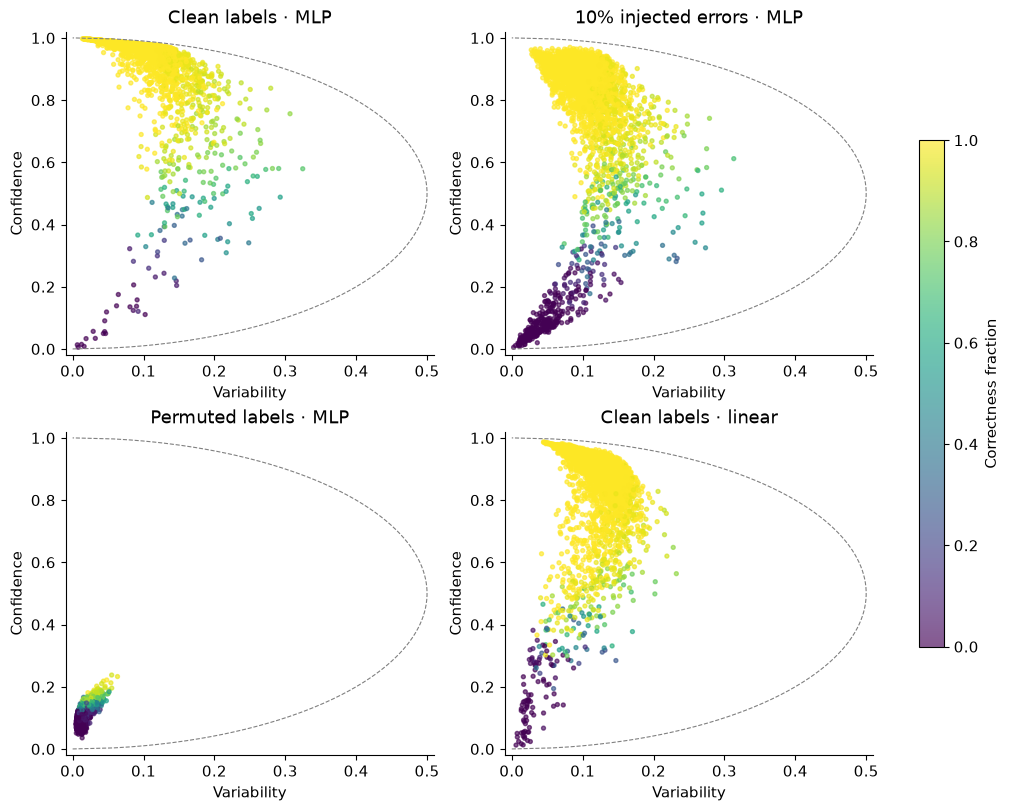

In [44]:
def draw_map(ax, stats, title, replicate=0):
    points = ax.scatter(stats['variability'][replicate], stats['confidence'][replicate], c=stats['correctness'][replicate], s=8, cmap='viridis', vmin=0, vmax=1, alpha=0.65, rasterized=True)
    mean = cart_torch.linspace(0, 1, 301)
    ax.plot(cart_torch.sqrt(mean * (1 - mean)), mean, color='gray', lw=0.8, ls='--')
    ax.set(title=title, xlabel='Variability', ylabel='Confidence', xlim=(-0.01, 0.51), ylim=(-0.02, 1.02))
    return points

cart_fig, cart_axes = cart_plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

for cart_ax, cart_name, cart_title in zip(cart_axes.flat, ('clean', 'noisy', 'shuffled', 'linear'), ('Clean labels · MLP', '10% injected errors · MLP', 'Permuted labels · MLP', 'Clean labels · linear')):
    points = draw_map(cart_ax, mapping['statistics'][cart_name]['end'], cart_title)

cart_fig.colorbar(points, ax=cart_axes, label='Correctness fraction', shrink=0.7)

cart_show_figure(cart_fig, 'cartography_maps')

### Read a point before naming a region

At the upper left, the assigned label receives high probability throughout the
recorded window. At the lower left, it receives low probability throughout.
The right-hand region contains substantial change over time. That change can
include a smooth learning transition; it need not mean the image is ambiguous
to a human, or that the model oscillates between answers.

The shuffled-label map has a different interpretation from the clean-label map.
Its labels no longer provide a reliable digit-recognition target. A visually
structured map alone cannot establish that its regions are useful. Check the
training curves, then later its held-out predictions against original labels.
The linear comparison changes the learner while keeping data and optimizer
settings fixed.

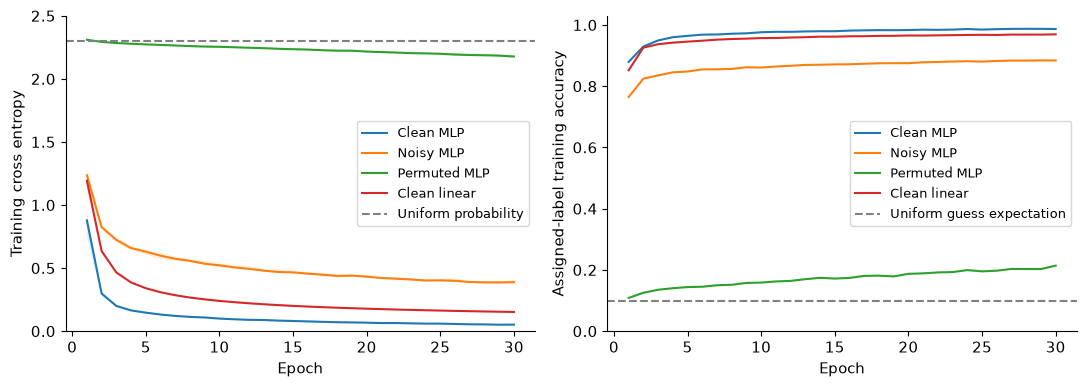

In [45]:
cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(11, 4))

for cart_name, cart_label in (('clean', 'Clean MLP'), ('noisy', 'Noisy MLP'), ('shuffled', 'Permuted MLP'), ('linear', 'Clean linear')):
    loss = mapping['runs'][cart_name]['loss']
    cart_axes[0].plot(range(1, 31), loss.mean(1), label=cart_label)
    cart_axes[0].fill_between(range(1, 31), loss.min(1).values, loss.max(1).values, alpha=0.12)
    correct = (mapping['runs'][cart_name]['end_logits'].argmax(-1) == cart_train[{'clean': 'y', 'noisy': 'noisy_y', 'shuffled': 'shuffled_y', 'linear': 'y'}[cart_name]]).float().mean(-1)
    cart_axes[1].plot(range(1, 31), correct.mean(1), label=cart_label)

cart_axes[0].axhline(cart_math.log(10), color='gray', ls='--', label='Uniform probability')

cart_axes[1].axhline(0.1, color='gray', ls='--', label='Uniform guess expectation')

cart_axes[0].set(xlabel='Epoch', ylabel='Training cross entropy', ylim=(0, 2.5))

cart_axes[1].set(xlabel='Epoch', ylabel='Assigned-label training accuracy', ylim=(0, 1.03))

cart_axes[0].legend(fontsize=9)

cart_axes[1].legend(fontsize=9)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_training')

### When was the measurement taken?

The next plots compare the two logging conventions for the same clean model.
Each point now represents one example measured twice. The identity line would
mean exact agreement. Then compare early, full and late training windows.
A repeated final checkpoint is the control: it contains no training history
and its variability is zero, even for an incorrectly classified image.

Forecast variation across seeds without choosing the most attractive map.

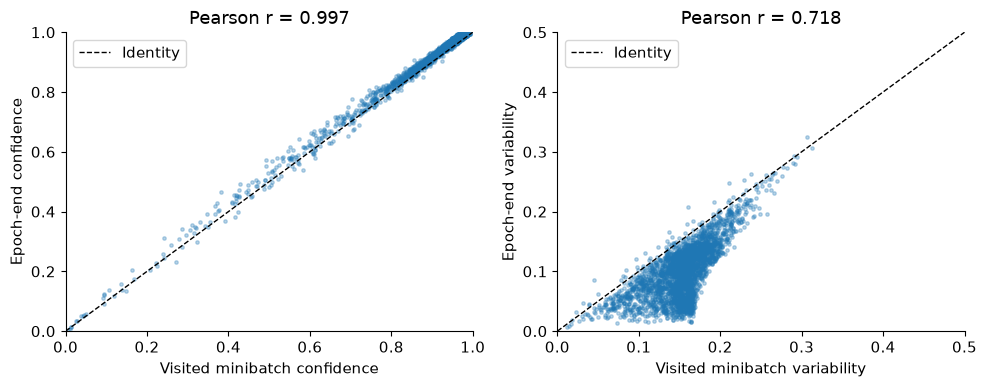

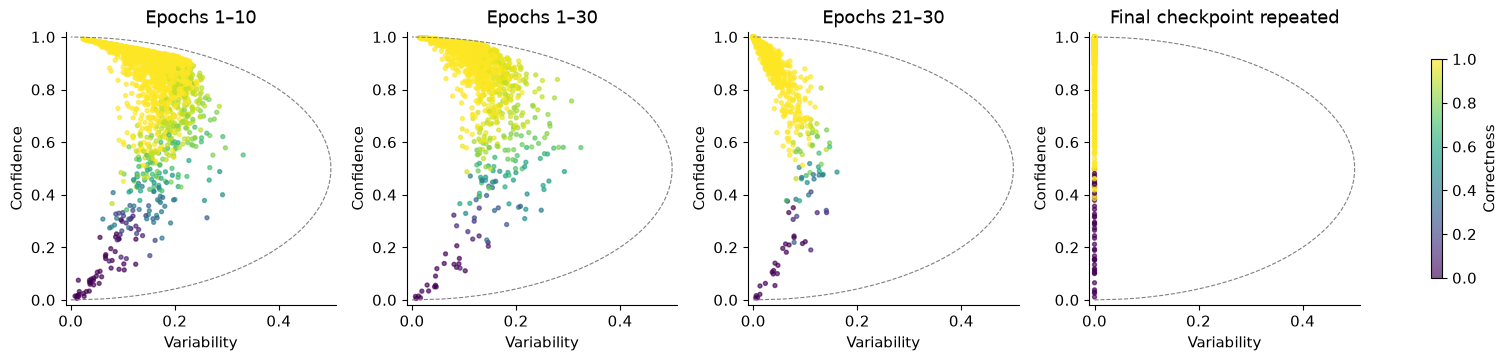

In [46]:
cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(10, 4))

for cart_ax, metric in zip(cart_axes, ('confidence', 'variability')):
    online = mapping['statistics']['clean']['online'][metric][0]
    end = mapping['statistics']['clean']['end'][metric][0]
    upper = 1 if metric == 'confidence' else 0.5
    cart_ax.scatter(online, end, s=6, alpha=0.3)
    cart_ax.plot([0, upper], [0, upper], 'k--', lw=1, label='Identity')
    correlation = float(cart_torch.corrcoef(cart_torch.stack([online, end]))[0, 1])
    cart_ax.set(xlabel=f'Visited minibatch {metric}', ylabel=f'Epoch-end {metric}', title=f'Pearson r = {correlation:.3f}', xlim=(0, upper), ylim=(0, upper))
    cart_ax.legend()

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_logging')

cart_fig, cart_axes = cart_plt.subplots(1, 4, figsize=(15, 3.5), constrained_layout=True)

for cart_ax, stats, cart_title in zip(cart_axes, [mapping['windows']['early'], mapping['statistics']['clean']['end'], mapping['windows']['late'], mapping['windows']['repeated_final']], ['Epochs 1–10', 'Epochs 1–30', 'Epochs 21–30', 'Final checkpoint repeated']):
    points = draw_map(cart_ax, stats, cart_title)

cart_fig.colorbar(points, ax=cart_axes, label='Correctness', shrink=0.8)

cart_show_figure(cart_fig, 'cartography_windows')

<details><summary>Interpretation - what changed most?</summary>

In the reference run, online and epoch-end confidence correlate at about 0.997,
but variability correlates at about 0.718. The first convention includes the
model before it has learned from many first-epoch minibatches. This need not
preserve a ranking based on temporal standard deviation.

The late-window map asks about a different part of learning. Its smaller
variability does not prove those examples were always easy. Keep the epoch
window with the map whenever reporting a result.

</details>

### How stable is the map across runs?

Correlation asks whether scores move together across all examples. Jaccard
asks whether two rankings actually choose the same retained set. High overall
correlation does not force the examples near a selection cutoff to agree.
The diagonal is the identical-run control; a random one-third set has expected
intersection near $N/9$, giving a large-$N$ Jaccard reference near $1/5$.

Predict how early and late windows change variability for a slowly learned image.

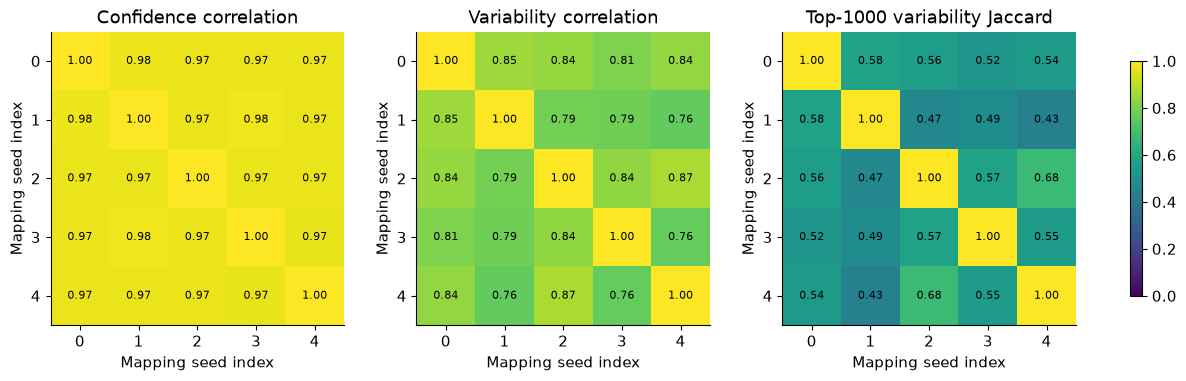

In [47]:
stats = mapping['statistics']['clean']['end']

cart_fig, cart_axes = cart_plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)

for cart_ax, metric in zip(cart_axes[:2], ('confidence', 'variability')):
    matrix = cart_torch.corrcoef(stats[metric])
    image = cart_ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    cart_ax.set(title=f'{metric.title()} correlation', xlabel='Mapping seed index', ylabel='Mapping seed index')
    cart_ax.set_xticks(range(5))
    cart_ax.set_yticks(range(5))
    for cart_i in range(5):
        for j in range(5):
            cart_ax.text(j, cart_i, f'{matrix[cart_i, j]:.2f}', ha='center', va='center', fontsize=8)

cart_selected = [select_indices(row, 1000) for row in stats['variability']]

jaccard = cart_torch.stack([cart_torch.stack([selection_overlap(a, b) for b in cart_selected]) for a in cart_selected])

cart_axes[2].imshow(jaccard, vmin=0, vmax=1, cmap='viridis')

cart_axes[2].set(title='Top-1000 variability Jaccard', xlabel='Mapping seed index', ylabel='Mapping seed index')

cart_axes[2].set_xticks(range(5))

cart_axes[2].set_yticks(range(5))

for cart_i in range(5):
    for j in range(5):
        cart_axes[2].text(j, cart_i, f'{jaccard[cart_i, j]:.2f}', ha='center', va='center', fontsize=8)

cart_fig.colorbar(image, ax=cart_axes, shrink=0.8)

cart_show_figure(cart_fig, 'cartography_seed_stability')

### Does a different measurement select the same data?

The next comparison changes one measurement choice while keeping the underlying
clean run paired by seed. Each cell averages five paired comparisons with the
full-window epoch-end map. Confidence/variability columns are Pearson
correlations; the remaining columns are top-1,000 set overlaps. The identical
measurement is a control with value one throughout. An undefined correlation
is left blank: a constant variability vector has no correlation coefficient.

The repeated-checkpoint variability ranking consists entirely of ties. Its
selected set therefore reflects our source-order tie rule, not a measured
learning difficulty. This is a useful example of a perfectly reproducible
selection that has no temporal information behind it.

Predict agreement across logging conventions, architecture and seeds; identify which comparisons reuse the same images.

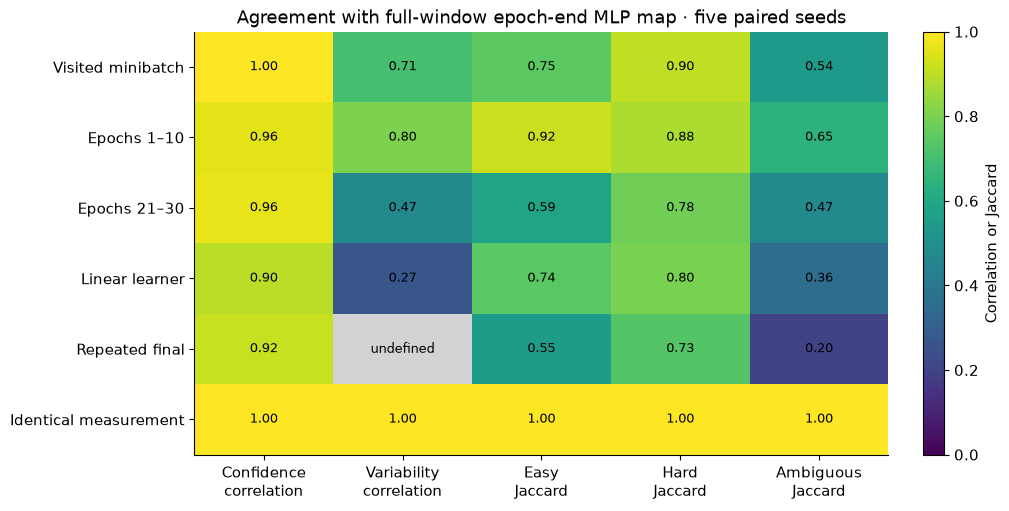

In [48]:
alternatives = {'Visited minibatch': mapping['statistics']['clean']['online'], 'Epochs 1–10': mapping['windows']['early'], 'Epochs 21–30': mapping['windows']['late'], 'Linear learner': mapping['statistics']['linear']['end'], 'Repeated final': mapping['windows']['repeated_final'], 'Identical measurement': stats}

comparison = []

for cart_name, other in alternatives.items():
    cart_rows = []
    for cart_replicate in range(5):
        cart_values = []
        for metric in ('confidence', 'variability'):
            left, right = (stats[metric][cart_replicate], other[metric][cart_replicate])
            cart_values.append(float(cart_torch.corrcoef(cart_torch.stack([left, right]))[0, 1]) if right.std() > 0 else float('nan'))
        for metric, largest in (('confidence', True), ('confidence', False), ('variability', True)):
            left = select_indices(stats[metric][cart_replicate], 1000, largest=largest)
            right = select_indices(other[metric][cart_replicate], 1000, largest=largest)
            cart_values.append(float(selection_overlap(left, right)))
        cart_rows.append(cart_values)
    comparison.append(cart_torch.tensor(cart_rows).mean(0))

comparison = cart_torch.stack(comparison)

cart_fig, cart_ax = cart_plt.subplots(figsize=(10, 5), constrained_layout=True)

colormap = cart_plt.colormaps['viridis'].copy()

colormap.set_bad('lightgray')

image = cart_ax.imshow(comparison, vmin=0, vmax=1, cmap=colormap, aspect='auto')

cart_ax.set_yticks(range(len(alternatives)), labels=list(alternatives))

cart_ax.set_xticks(range(5), labels=['Confidence\ncorrelation', 'Variability\ncorrelation', 'Easy\nJaccard', 'Hard\nJaccard', 'Ambiguous\nJaccard'])

for cart_i in range(len(alternatives)):
    for j in range(5):
        cart_label = f'{comparison[cart_i, j]:.2f}' if cart_torch.isfinite(comparison[cart_i, j]) else 'undefined'
        cart_ax.text(j, cart_i, cart_label, ha='center', va='center', fontsize=9)

cart_ax.set_title('Agreement with full-window epoch-end MLP map · five paired seeds')

cart_fig.colorbar(image, ax=cart_ax, label='Correlation or Jaccard')

cart_show_figure(cart_fig, 'cartography_measurement_stability')

### Find the images behind the coordinates

Inspect the first four images in each ranking. The fourth row is a fixed random
control. The next figure follows those same images across every epoch. Compare
a steady rise with an actual reversal, and compare assigned-label probability
with the maximum probability over classes. A disagreement between the two curves
means the model preferred a different label.

The top of a ranking is shown to help interpret the rule; it is not a random
sample of the entire retained set.

Forecast class counts and image appearances behind each ranked region.

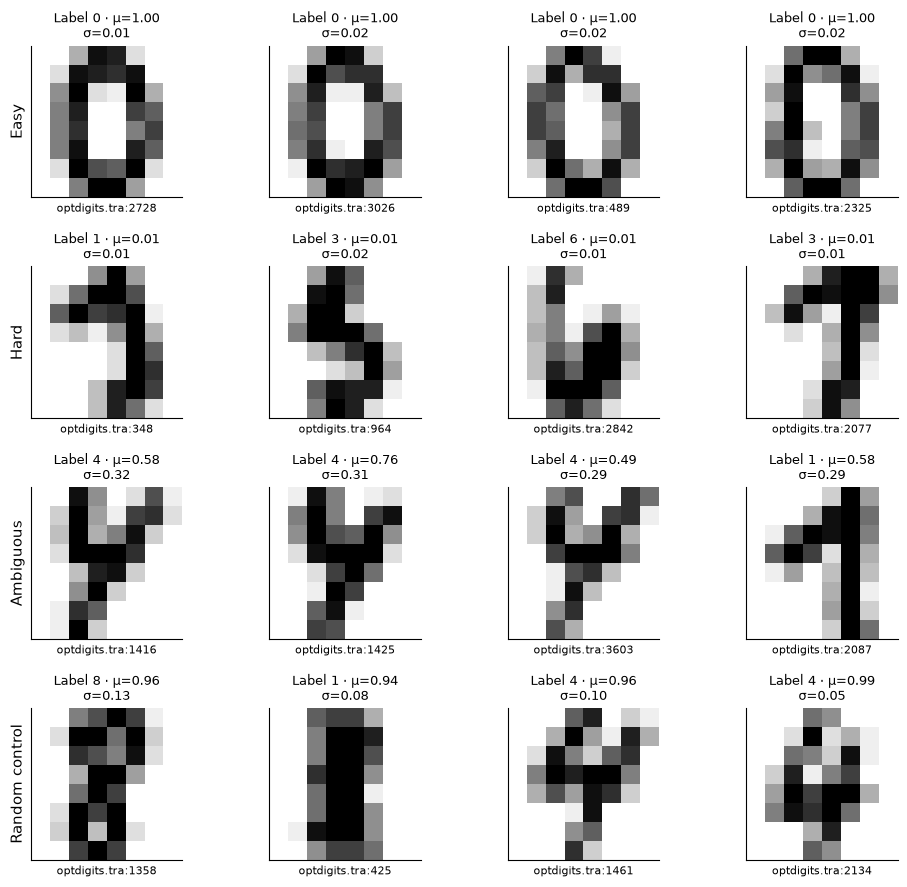

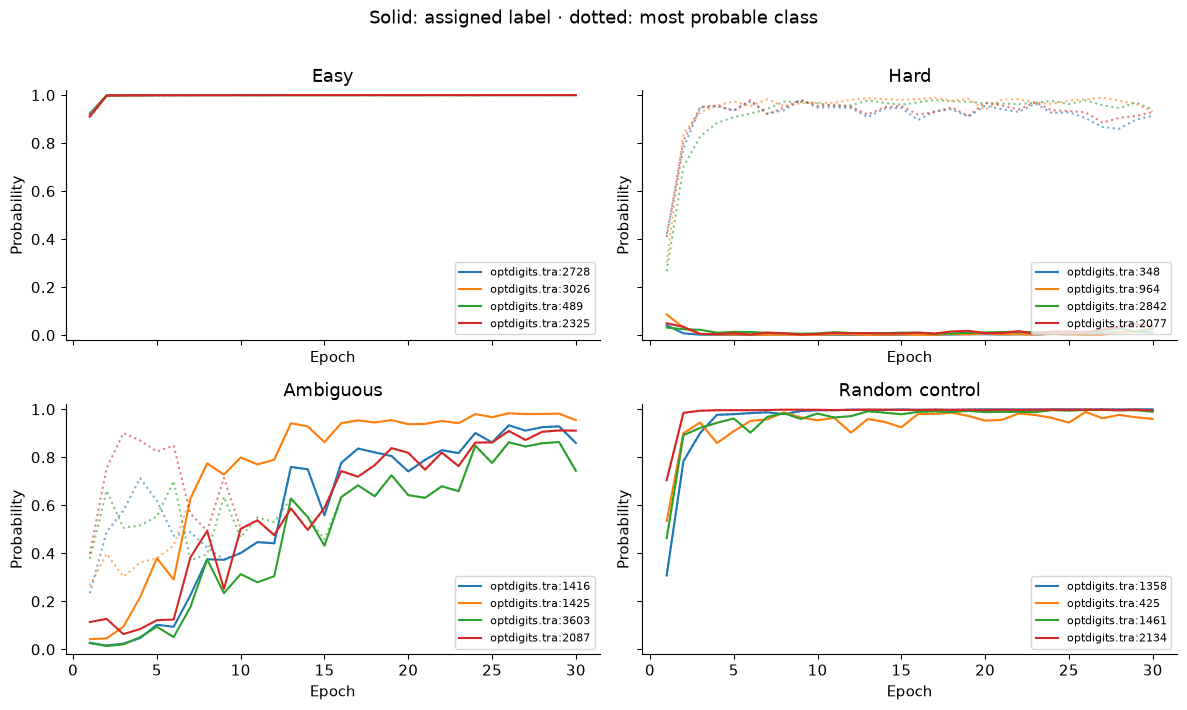

In [49]:
cart_gallery = {'Easy': select_indices(stats['confidence'][0], 4), 'Hard': select_indices(stats['confidence'][0], 4, largest=False), 'Ambiguous': select_indices(stats['variability'][0], 4), 'Random control': cart_torch.randperm(3000, generator=cart_torch.Generator().manual_seed(166200))[:4]}

cart_fig, cart_axes = cart_plt.subplots(4, 4, figsize=(10, 9))

for cart_row, (region, indices) in enumerate(cart_gallery.items()):
    for cart_ax, cart_index in zip(cart_axes[cart_row], indices):
        cart_ax.imshow(cart_train['x'][cart_index].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
        cart_ax.set_title(f"Label {int(cart_train['y'][cart_index])} · μ={stats['confidence'][0, cart_index]:.2f}\nσ={stats['variability'][0, cart_index]:.2f}", fontsize=9)
        cart_ax.set_xlabel(cart_train['ids'][cart_index], fontsize=8)
        cart_ax.set_xticks([])
        cart_ax.set_yticks([])
    cart_axes[cart_row, 0].set_ylabel(region, fontsize=11)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_region_gallery')

probabilities = gold_probabilities(mapping['runs']['clean']['end_logits'], cart_train['y'].expand(5, -1))

top_probability = mapping['runs']['clean']['end_logits'].softmax(-1).max(-1).values

cart_fig, cart_axes = cart_plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)

for cart_ax, (region, indices) in zip(cart_axes.flat, cart_gallery.items()):
    for cart_index in indices:
        line, = cart_ax.plot(range(1, 31), probabilities[:, 0, cart_index], label=cart_train['ids'][cart_index])
        cart_ax.plot(range(1, 31), top_probability[:, 0, cart_index], ls=':', color=line.get_color(), alpha=0.6)
    cart_ax.set(title=region, xlabel='Epoch', ylabel='Probability', ylim=(-0.02, 1.02))
    cart_ax.legend(fontsize=8, loc='lower right')

cart_fig.suptitle('Solid: assigned label · dotted: most probable class', y=1.01)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_region_trajectories')

### Diagnose the controlled errors

Each noisy model starts from the same initialization and uses the same example
order as its paired clean model. We rank by low confidence **in the changed
assigned label**. Compare against random inspection and the confidence ranking
from the uncorrupted training run. The latter asks whether the original digit
was already difficult before its label was changed.

The known injected-error mask is available only because we created the errors.
For naturally labeled data, low-confidence examples need inspection; a score
alone does not tell you whether the label, the image or the learner is at fault.

Predict injected-noise retrieval against random selection; distinguish known synthetic errors from natural annotation errors.

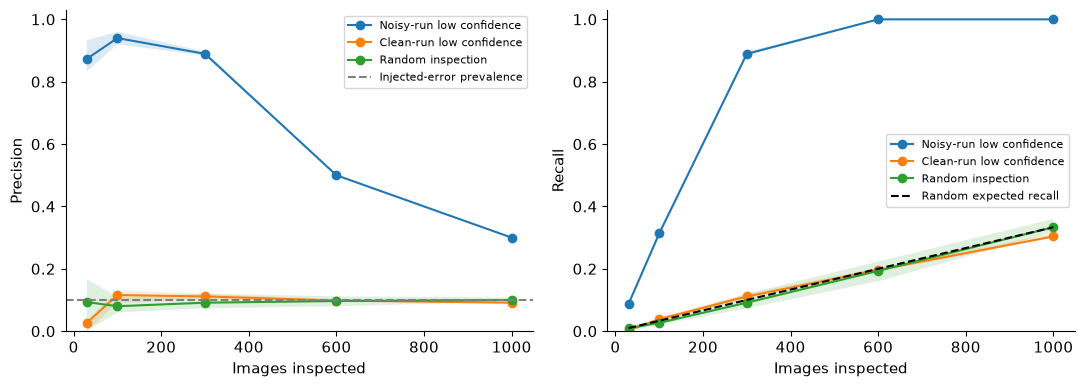

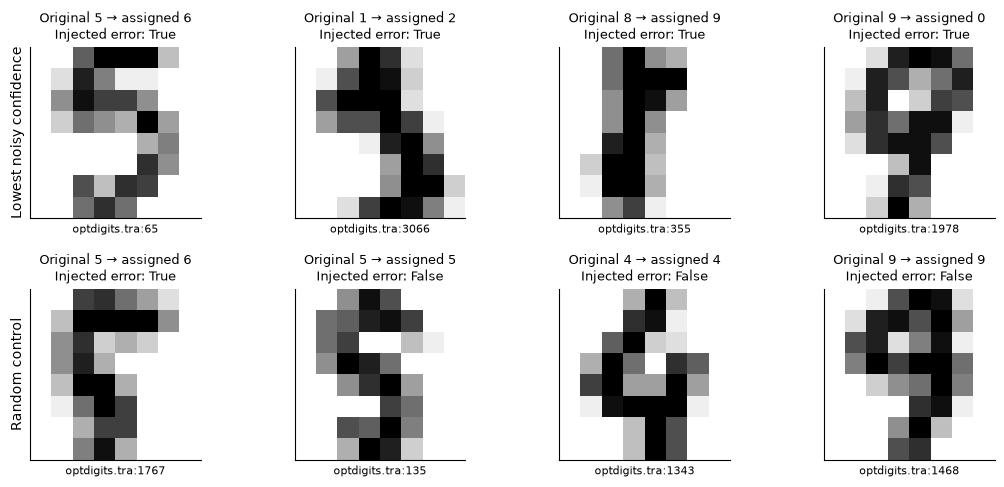

In [50]:
cart_budgets = mapping['diagnosis_budgets']

cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(11, 4))

for method, cart_label in (('noisy', 'Noisy-run low confidence'), ('clean', 'Clean-run low confidence'), ('random', 'Random inspection')):
    for cart_ax, metric in zip(cart_axes, ('precision', 'recall')):
        cart_values = cart_torch.stack([mapping['diagnosis'][str(i)][method][metric] for i in range(5)])
        cart_ax.plot(cart_budgets, cart_values.mean(0), 'o-', label=cart_label)
        cart_ax.fill_between(cart_budgets, cart_values.min(0).values, cart_values.max(0).values, alpha=0.15)
        cart_ax.set(xlabel='Images inspected', ylabel=metric.title(), ylim=(0, 1.03))

cart_axes[0].axhline(0.1, color='gray', ls='--', label='Injected-error prevalence')

cart_axes[1].plot(cart_budgets, cart_budgets / 3000, 'k--', label='Random expected recall')

for cart_ax in cart_axes:
    cart_ax.legend(fontsize=8)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_error_retrieval')

indices = select_indices(mapping['statistics']['noisy']['end']['confidence'][0], 4, largest=False)

random = cart_torch.randperm(3000, generator=cart_torch.Generator().manual_seed(166201))[:4]

cart_fig, cart_axes = cart_plt.subplots(2, 4, figsize=(11, 5))

for cart_row, (cart_title, cart_chosen) in enumerate((('Lowest noisy confidence', indices), ('Random control', random))):
    for cart_ax, cart_index in zip(cart_axes[cart_row], cart_chosen):
        cart_ax.imshow(cart_train['x'][cart_index].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
        cart_ax.set_title(f"Original {int(cart_train['y'][cart_index])} → assigned {int(cart_train['noisy_y'][cart_index])}\nInjected error: {bool(cart_train['changed'][cart_index])}", fontsize=9)
        cart_ax.set_xlabel(cart_train['ids'][cart_index], fontsize=8)
        cart_ax.set_xticks([])
        cart_ax.set_yticks([])
    cart_axes[cart_row, 0].set_ylabel(cart_title, fontsize=10)

cart_fig.tight_layout()

cart_show_figure(cart_fig, 'cartography_noise_gallery')

<details><summary>Expected output and interpretation</summary>

At an inspection budget of 300, the five noisy-run rankings have precision
about 0.883–0.897. Since there are exactly 300 injected errors, recall has the
same numerical value at this particular budget. That equality would disappear
at a different budget. A random ranking has expected precision 0.1.

The misses and false positives matter. Neither a 300-image inspection budget
nor a low-confidence cutoff establishes that every retrieved example is wrong.
The untouched source labels are comparison labels, not a fresh human audit.

</details>

## 3️⃣ Does selecting a region help a new model?

A map is descriptive. A claim about which data to keep requires a new training
experiment. We fix the clean MLP map from seed 161100 before opening holdout
predictions. We retain 300, 1,000 or 2,000 examples by each region ranking and
train five fresh models for every selection.

A first complication is **class coverage**. Globally selecting high-confidence
examples can almost eliminate a class. Uniform random subsets control retained
size, but they do not reproduce that class imbalance. We therefore add random
subsets with exactly the selected set's label counts. These controls may share
examples with the selected set; disjointness would change the sampling question.

Mapping seeds are separate from retraining seeds. We retain all five results,
including failures; the best seed is never selected by a holdout score.

### Exercise - construct a class-matched random control

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Given observed labels, one selected index vector and a fresh seed, draw a
uniform random subset within each class with exactly the selected counts.
Return sorted canonical indices without replacement. The control uses observed
labels; it does not consult model scores or held-out performance.

Predict which class-count equality must hold exactly under matched random selection.

In [51]:
def matched_random_indices(labels: cart_Tensor, selected: cart_Tensor, seed: int) -> cart_Tensor:
    """Uniform sampling within each observed class, matching selected label counts."""
    if selected.ndim != 1 or selected.unique().numel() != selected.numel():
        raise ValueError('Selected training indices must be a vector without duplicates.')
    generator = cart_torch.Generator().manual_seed(seed)
    result = []
    for label in labels.unique(sorted=True):
        candidates = cart_torch.where(labels == label)[0]
        count = int((labels[selected] == label).sum())
        order = cart_torch.randperm(len(candidates), generator=generator)
        result.append(candidates[order[:count]])
    return cart_torch.cat(result).sort().values

cart_tests.test_matched_random_indices(matched_random_indices)

matched_random_indices passed: exact class counts, no duplicates and independent seeded sampling.


<details>
<summary>Help - where should I start?</summary>

Count selected examples per label. Permute all candidates in that label with
a local generator, take the required number, and concatenate. Sorting the final
indices establishes the canonical order before the training loop shuffles them.

</details>

<details>
<summary>Expected output</summary>

A selection with class counts `[2, 3, 1]` yields a random control with exactly
those counts for every tested seed, with no duplicate examples.

</details>

### Exercise - evaluate every held-out example

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Evaluate fixed parameter sets on a held-out input matrix. Return logits,
per-example correctness and cross entropy, average accuracy/loss and classwise
accuracy. This function must not train, choose a seed or select examples.
Classwise means assume each evaluated class is represented in the holdout.

Predict why evaluation batch shape must preserve separate ensemble models and image denominators.

In [52]:
def evaluate_models(parameters: dict[str, cart_Tensor], x: cart_Tensor, labels: cart_Tensor) -> dict[str, cart_Tensor]:
    """One fixed holdout, evaluated for every model; no selection or fitting."""
    models = len(next(iter(parameters.values())))
    with cart_torch.no_grad():
        logits = batched_logits(parameters, x.expand(models, -1, -1))
        repeated_labels = labels.expand(models, -1)
        correct = logits.argmax(dim=-1) == repeated_labels
        losses = F.cross_entropy(logits.flatten(0, 1), repeated_labels.flatten(), reduction='none').reshape_as(repeated_labels)
        class_accuracy = cart_torch.stack([correct[:, labels == label].float().mean(dim=1) for label in range(logits.shape[-1])], dim=-1)
    return dict(logits=logits, correct=correct, loss_per_example=losses, accuracy=correct.float().mean(dim=1), cross_entropy=losses.mean(dim=1), class_accuracy=class_accuracy)

cart_tests.test_evaluate_models(evaluate_models)

evaluate_models passed: every model, every held-out example and independent logistic-loss oracle.


<details>
<summary>Help - where should I start?</summary>

Expand the holdout along the model axis, run the forward function under
`no_grad`, and retain the per-example results before taking means. Cross entropy
uses the assigned true holdout labels, not the argmax predictions.

</details>

<details>
<summary>Expected output</summary>

Two fixture models obtain accuracies one and zero on exactly the same two
examples. Their losses match independent analytic logistic-loss values.

</details>

### Fix selections, train all models, then open the holdouts

The code below makes every selection first, then trains 120 new networks. At
each size it includes the three regions, three class-matched controls, and a
uniform random control. Five full-pool models provide a reference.

The final ten runs address optimizer budget. A 1,000-image subset gets eight
minibatches per epoch, versus 24 for the full pool. Training the ambiguous
subset and its matched random controls for 90 epochs gives them the same 720
updates as 30 full-pool epochs. This controls update count for this one
comparison; it is not a claim that all learning conditions are equivalent.

The complete selected sets and final parameters are saved before computing any
holdout model predictions. The save is a reproducibility aid; the plots below
are calculated from the actual models trained in these cells.

In [53]:
cart_methods.matched_random_indices = matched_random_indices

cart_methods.evaluate_models = evaluate_models

def make_selections(train, mapping, methods):
    stats = mapping['statistics']['clean']['end']
    selections = {'full': cart_torch.arange(len(train['y'])).expand(5, -1).clone()}
    for size_index, size in enumerate((300, 1000, 2000)):
        for region_index, region in enumerate(('easy', 'hard', 'ambiguous')):
            score = stats['variability' if region == 'ambiguous' else 'confidence'][0]
            selected = methods.select_indices(score, size, largest=region != 'hard').sort().values
            name = f'{region}_{size}'
            selections[name] = selected.expand(5, -1).clone()
            selections[f'{name}_matched'] = cart_torch.stack([methods.matched_random_indices(train['y'], selected, 161300 + 1000 * region_index + 10 * size_index + replicate) for replicate in range(5)])
        selections[f'uniform_{size}'] = cart_torch.stack([cart_torch.randperm(len(train['y']), generator=cart_torch.Generator().manual_seed(165000 + 10 * size_index + replicate))[:size].sort().values for replicate in range(5)])
    return selections

def retrain_selections(train, mapping, methods, directory):
    selections = make_selections(train, mapping, methods)
    cart_torch.save(selections, directory / 'selections_before_refits.pt')
    fits = {}
    seeds = list(range(161200, 161205))
    for name, indices in selections.items():
        fits[name] = methods.train_ensemble(train['x'][indices], train['y'][indices], seeds, record=False)
    for source in ('ambiguous_1000', 'ambiguous_1000_matched'):
        indices = selections[source]
        name = f'{source}_equal_updates'
        fits[name] = methods.train_ensemble(train['x'][indices], train['y'][indices], seeds, epochs=90, record=False)
        cart_torch.testing.assert_close(fits[name]['loss'][:30], fits[source]['loss'], rtol=0, atol=0)
        selections[name] = indices.clone()
    result = dict(phase='ALL_SELECTIONS_AND_FRESH_TRAINING_COMPLETE', ids=train['ids'], selections=selections, fits=fits, heldout_predictions_computed=False, refits=sum((len(run['seeds']) for run in fits.values())))
    if result['refits'] != 120:
        raise ValueError('The complete selection study requires 120 fresh refits.')
    cart_torch.save(result, directory / 'prepared.pt')
    return result

cart_prepared = retrain_selections(cart_train, mapping, cart_methods, native_directory)

cart_boundary = {'phase': cart_prepared['phase'], 'heldout_predictions_computed': False, 'mapping_sha256': cart_hashlib.sha256((native_directory / 'mapping.pt').read_bytes()).hexdigest(), 'prepared_sha256': cart_hashlib.sha256((native_directory / 'prepared.pt').read_bytes()).hexdigest()}

(cart_OUTPUT / 'before_evaluation.json').write_text(cart_json.dumps(cart_boundary, indent=2) + '\n')

print('All selections and 120 fresh refits saved. Holdout predictions have not been computed.')

All selections and 120 fresh refits saved. Holdout predictions have not been computed.


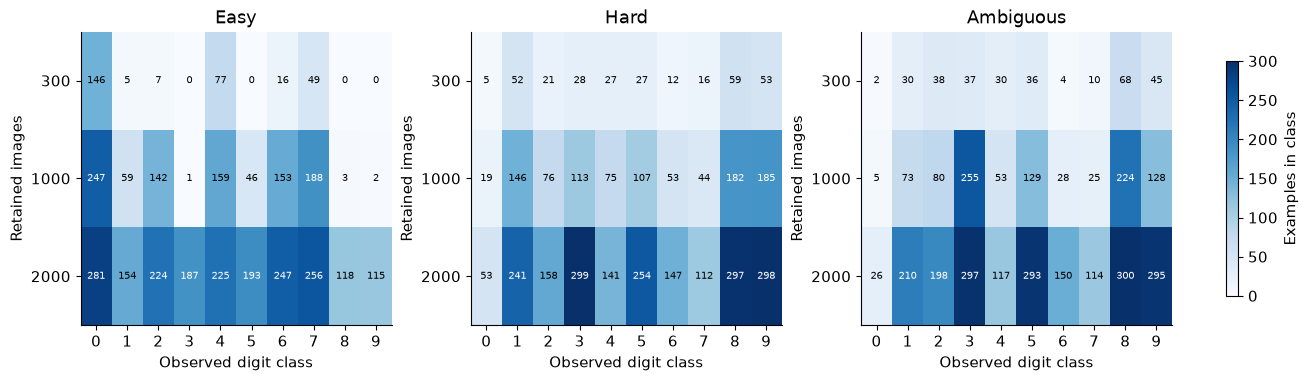

In [54]:
cart_fig, cart_axes = cart_plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)

for cart_ax, region in zip(cart_axes, ('easy', 'hard', 'ambiguous')):
    cart_counts = cart_torch.stack([cart_torch.bincount(cart_train['y'][cart_prepared['selections'][f'{region}_{n}'][0]], minlength=10) for n in (300, 1000, 2000)])
    image = cart_ax.imshow(cart_counts, vmin=0, vmax=300, cmap='Blues', aspect='auto')
    cart_ax.set(title=region.title(), xlabel='Observed digit class', ylabel='Retained images')
    cart_ax.set_xticks(range(10))
    cart_ax.set_yticks(range(3), labels=[300, 1000, 2000])
    for cart_i in range(3):
        for j in range(10):
            cart_ax.text(j, cart_i, int(cart_counts[cart_i, j]), ha='center', va='center', fontsize=7, color='white' if cart_counts[cart_i, j] > 170 else 'black')

cart_fig.colorbar(image, ax=cart_axes, label='Examples in class', shrink=0.8)

cart_show_figure(cart_fig, 'cartography_class_counts')

The easy 300-image selection contains **no examples of digits 3, 5, 8 or 9**
in the reference run. Its matched control has the same omissions. The one-third
ambiguous selection heavily favors some classes and contains only five zeros.
This is why a size-matched uniform control and a class-matched control answer
different questions. These counts come entirely from training data.

In [55]:
def cart_evaluate_study(mapping, prepared, evaluation, methods, directory):
    if prepared['phase'] != 'ALL_SELECTIONS_AND_FRESH_TRAINING_COMPLETE' or prepared['heldout_predictions_computed']:
        raise ValueError('Save every selection and fresh training run before evaluating holdouts.')
    output = dict(holdout_ids={name: split['ids'] for name, split in evaluation.items()}, mapping={}, refits={})
    for category, runs in (('mapping', mapping['runs']), ('refits', prepared['fits'])):
        for name, run in runs.items():
            output[category][name] = {split_name: methods.evaluate_models(run['parameters'], split['x'], split['y']) for split_name, split in evaluation.items()}
    output['evaluated_models'] = 140
    output['evaluation_used_for_selection'] = False
    cart_torch.save(output, directory / 'evaluated.pt')
    return output

evaluation = load_evaluation()

cart_evaluated = cart_evaluate_study(mapping, cart_prepared, evaluation, cart_methods, native_directory)

print('Evaluated all 140 models on 823 same-source and 1797 separate-writer images.')

Evaluated all 140 models on 823 same-source and 1797 separate-writer images.


### Do the map controls generalize to original labels?

Here are the held-out results for the four mapping conditions, with all five
seeds visible. Holdout labels were never corrupted or shuffled. A shuffled-label
model can improve its training accuracy yet remain near chance on digit
recognition. This is the behavioral control behind the earlier map comparison.
The noisy model's loss of accuracy also shows that the injected errors were
not merely cosmetic changes to a scatter plot.

Forecast which classes lose accuracy under region selection and whether class matching explains the difference.

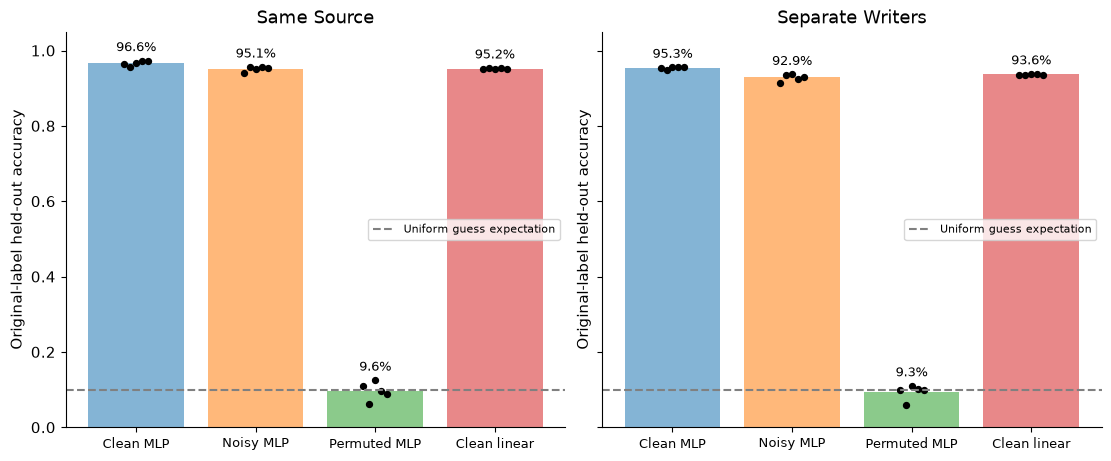

In [56]:
cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, constrained_layout=True)

conditions = ('clean', 'noisy', 'shuffled', 'linear')

for cart_ax, cart_split in zip(cart_axes, ('same_source', 'separate_writers')):
    for cart_index, cart_name in enumerate(conditions):
        cart_values = cart_evaluated['mapping'][cart_name][cart_split]['accuracy']
        cart_ax.bar(cart_index, cart_values.mean(), color=f'C{cart_index}', alpha=0.55)
        cart_ax.scatter(cart_index + cart_np.linspace(-0.1, 0.1, 5), cart_values, color='black', s=18)
        cart_ax.text(cart_index, float(cart_values.max()) + 0.025, f'{cart_values.mean():.1%}', ha='center', fontsize=9)
    cart_ax.axhline(0.1, color='gray', ls='--', label='Uniform guess expectation')
    cart_ax.set_xticks(range(4), labels=['Clean MLP', 'Noisy MLP', 'Permuted MLP', 'Clean linear'], fontsize=9)
    cart_ax.set(title=cart_split.replace('_', ' ').title(), ylabel='Original-label held-out accuracy', ylim=(0, 1.05))
    cart_ax.legend(fontsize=8, loc='center right')

cart_show_figure(cart_fig, 'cartography_mapping_generalization')

### Read all seeds, not just the winner

Each curve below shows the mean of five retraining runs, with the full range
shaded. This range describes these runs; it is not a confidence interval over
all possible datasets. For a fixed region, the selected set is shared across
seeds. Its matched controls also vary the sampled subset. Paired seeds share
initializations, but differing training inputs still change the optimization
path. The horizontal full-pool baseline uses all 3,000 images.

The second set of curves uses cross entropy. Accuracy can stay unchanged while
confidence on correct or incorrect predictions changes substantially.

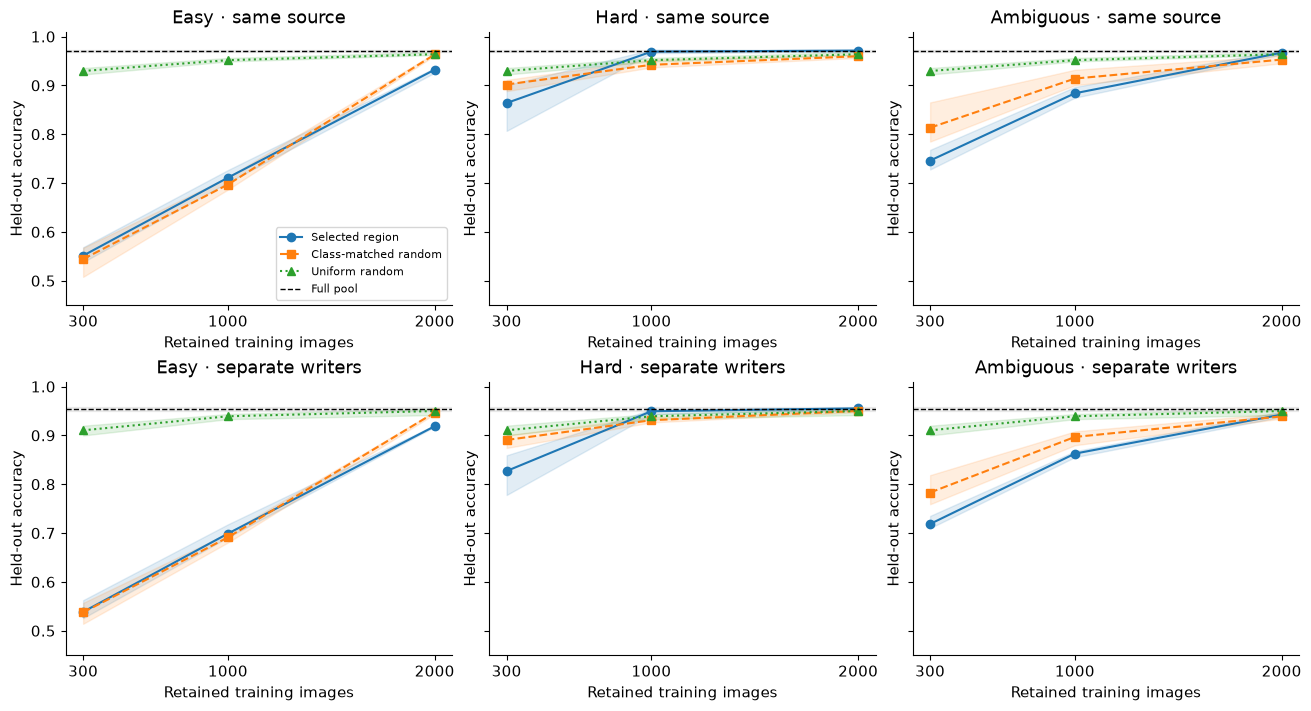

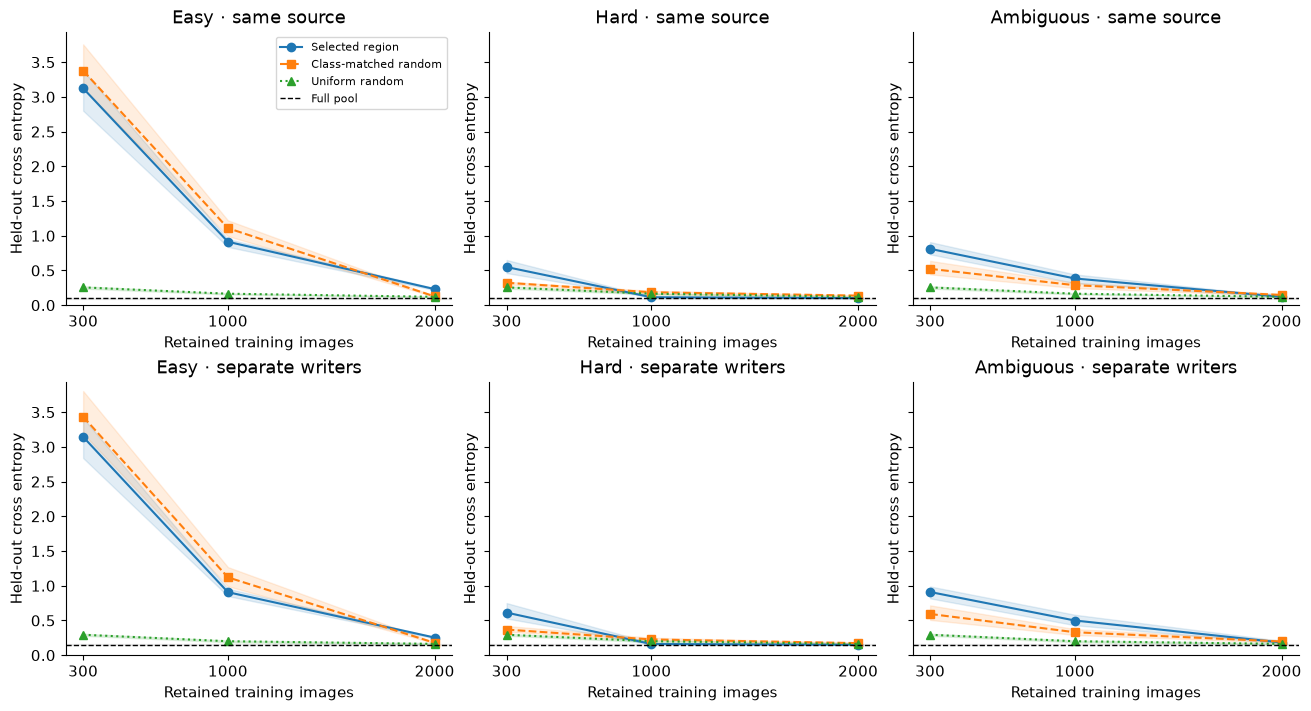

In [57]:
cart_sizes = (300, 1000, 2000)

for metric, ylabel, filename in (('accuracy', 'Held-out accuracy', 'cartography_selection_accuracy'), ('cross_entropy', 'Held-out cross entropy', 'cartography_selection_loss')):
    cart_fig, cart_axes = cart_plt.subplots(2, 3, figsize=(13, 7), sharey=True, constrained_layout=True)
    for cart_row, cart_split in enumerate(('same_source', 'separate_writers')):
        for cart_col, region in enumerate(('easy', 'hard', 'ambiguous')):
            cart_ax = cart_axes[cart_row, cart_col]
            for kind, cart_label, style in ((region, 'Selected region', 'o-'), (region + '_matched', 'Class-matched random', 's--'), ('uniform', 'Uniform random', '^:')):
                keys = [f'{region}_{n}_matched' if kind.endswith('_matched') else f'{kind}_{n}' for n in cart_sizes]
                cart_values = cart_torch.stack([cart_evaluated['refits'][key][cart_split][metric] for key in keys])
                line, = cart_ax.plot(cart_sizes, cart_values.mean(1), style, label=cart_label)
                cart_ax.fill_between(cart_sizes, cart_values.min(1).values, cart_values.max(1).values, alpha=0.13, color=line.get_color())
            full = cart_evaluated['refits']['full'][cart_split][metric]
            cart_ax.axhline(float(full.mean()), color='black', ls='--', lw=1, label='Full pool')
            cart_ax.axhspan(float(full.min()), float(full.max()), color='gray', alpha=0.12)
            cart_ax.set(title=f"{region.title()} · {cart_split.replace('_', ' ')}", xlabel='Retained training images', ylabel=ylabel)
            cart_ax.set_xticks(cart_sizes)
            if metric == 'accuracy':
                cart_ax.set_ylim(0.45, 1.01)
            else:
                cart_ax.set_ylim(bottom=0)
            if cart_row == 0 and cart_col == 0:
                cart_ax.legend(fontsize=8)
    cart_show_figure(cart_fig, filename)

<details><summary>Interpretation - did ambiguity win?</summary>

At 1,000 retained images, the separate-writer accuracy averages about **86.3%**
for high variability, **89.7%** for its class-matched random control, and **93.9%**
for uniform random selection. Low-confidence selection averages about **95.0%**,
close to the full-pool mean of **95.4%**. The larger 2,000-image selections tell
a different story, so do not summarize the entire experiment with one budget.

The paper found high-variability subsets useful for its NLP tasks and challenge
sets. That is a result to investigate, not a theorem about every dataset and
learner. This experiment uses a small digit network and a source-provided writer
split. It does not reproduce the paper's RoBERTa or natural-language OOD results.
Our own trajectories and class counts offer concrete reasons to be cautious
about transferring the word “ambiguous” across experiments.

</details>

### Does equalizing update count rescue the selection?

Compare the one-third ambiguous selection at 240 and 720 optimizer updates.
The matched random subsets get exactly the same two budgets. The full-pool
baseline has 720 updates. Longer training helps both one-third groups in this
run, but it does not reverse their ordering.

Forecast what changes when equal epochs become equal optimizer updates; identify the budget confound.

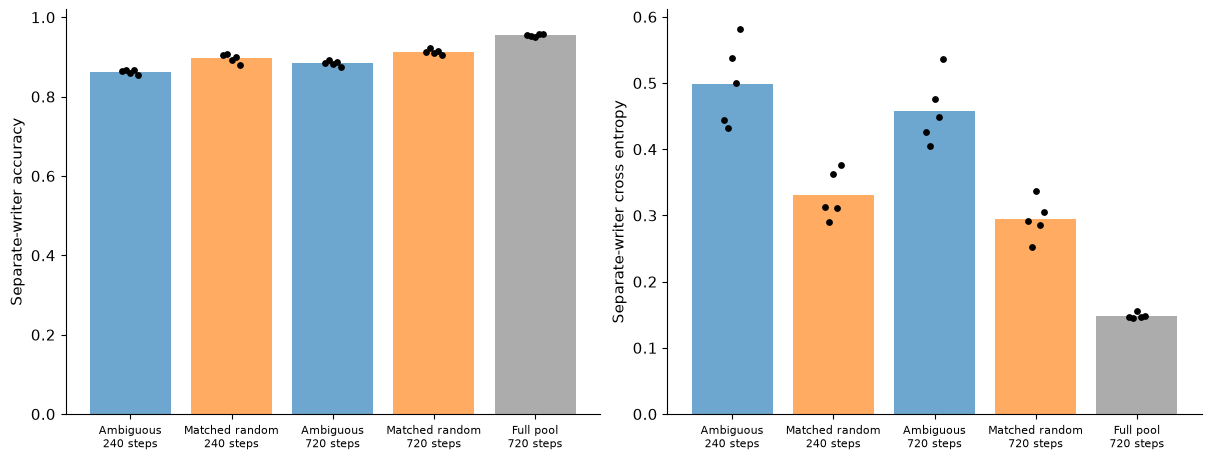

In [58]:
keys = ['ambiguous_1000', 'ambiguous_1000_matched', 'ambiguous_1000_equal_updates', 'ambiguous_1000_matched_equal_updates', 'full']

labels = ['Ambiguous\n240 steps', 'Matched random\n240 steps', 'Ambiguous\n720 steps', 'Matched random\n720 steps', 'Full pool\n720 steps']

cart_fig, cart_axes = cart_plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

for cart_ax, metric, ylabel in zip(cart_axes, ('accuracy', 'cross_entropy'), ('Separate-writer accuracy', 'Separate-writer cross entropy')):
    cart_values = cart_torch.stack([cart_evaluated['refits'][key]['separate_writers'][metric] for key in keys])
    cart_ax.bar(range(5), cart_values.mean(1), color=['C0', 'C1', 'C0', 'C1', 'gray'], alpha=0.65)
    for seed in range(5):
        cart_ax.scatter(cart_np.arange(5) + (seed - 2) * 0.04, cart_values[:, seed], color='black', s=15)
    cart_ax.set_xticks(range(5), labels=labels, fontsize=8)
    cart_ax.set_ylabel(ylabel)
    if metric == 'accuracy':
        cart_ax.set_ylim(0, 1.02)
    else:
        cart_ax.set_ylim(bottom=0)

cart_show_figure(cart_fig, 'cartography_equal_updates')

### Which classes and examples changed?

An average can hide a class that has nearly disappeared from the training set.
The first heatmap compares per-class accuracy for the one-third selections and
controls. The second figure pairs each selected model with the corresponding
full-pool seed and counts held-out examples that were gained or lost. A gain
means selected-only correct; a loss means full-pool-only correct. Shared errors
are excluded, so the two counts need not sum to the test-set size.

Predict paired correctness transitions rather than counting all repeated model/image predictions as independent images.

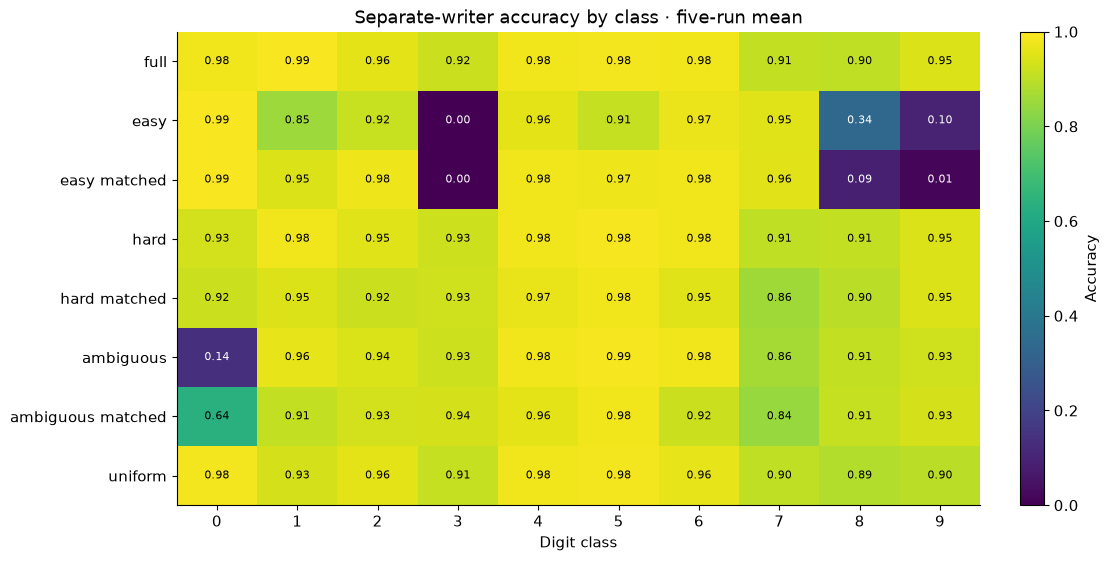

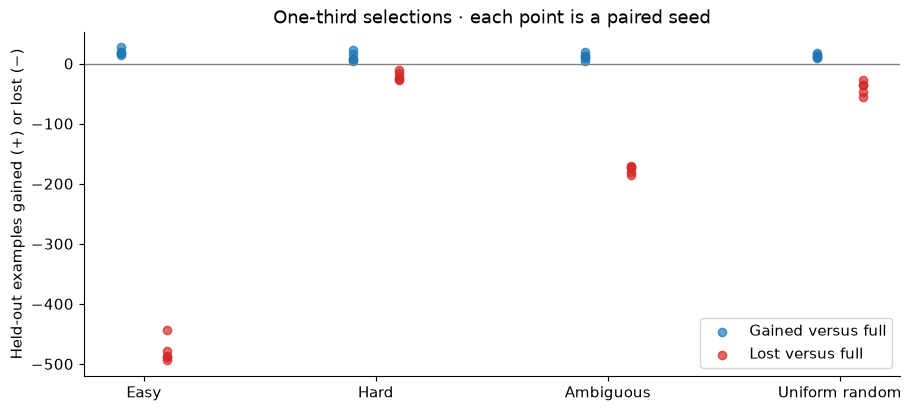

In [59]:
keys = ['full', 'easy_1000', 'easy_1000_matched', 'hard_1000', 'hard_1000_matched', 'ambiguous_1000', 'ambiguous_1000_matched', 'uniform_1000']

cart_values = cart_torch.stack([cart_evaluated['refits'][key]['separate_writers']['class_accuracy'].mean(0) for key in keys])

cart_fig, cart_ax = cart_plt.subplots(figsize=(11, 5.5), constrained_layout=True)

image = cart_ax.imshow(cart_values, cmap='viridis', vmin=0, vmax=1, aspect='auto')

cart_ax.set_xticks(range(10))

cart_ax.set_yticks(range(len(keys)), labels=[k.replace('_1000', '').replace('_', ' ') for k in keys])

cart_ax.set(xlabel='Digit class', title='Separate-writer accuracy by class · five-run mean')

for cart_i in range(len(keys)):
    for j in range(10):
        cart_ax.text(j, cart_i, f'{cart_values[cart_i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if cart_values[cart_i, j] < 0.6 else 'black')

cart_fig.colorbar(image, ax=cart_ax, label='Accuracy')

cart_show_figure(cart_fig, 'cartography_class_accuracy')

cart_fig, cart_ax = cart_plt.subplots(figsize=(9, 4), constrained_layout=True)

full_correct = cart_evaluated['refits']['full']['separate_writers']['correct']

for j, cart_name in enumerate(('easy', 'hard', 'ambiguous', 'uniform')):
    correct = cart_evaluated['refits'][f'{cart_name}_1000']['separate_writers']['correct']
    gains = (correct & ~full_correct).sum(1)
    losses = (~correct & full_correct).sum(1)
    cart_ax.scatter(cart_torch.full((5,), j - 0.1), gains, color='C0', alpha=0.7, label='Gained versus full' if j == 0 else None)
    cart_ax.scatter(cart_torch.full((5,), j + 0.1), -losses, color='C3', alpha=0.7, label='Lost versus full' if j == 0 else None)

cart_ax.axhline(0, color='gray', lw=1)

cart_ax.set_xticks(range(4), labels=['Easy', 'Hard', 'Ambiguous', 'Uniform random'])

cart_ax.set(ylabel='Held-out examples gained (+) or lost (−)', title='One-third selections · each point is a paired seed')

cart_ax.legend()

cart_show_figure(cart_fig, 'cartography_paired_changes')

### Try It Yourself - choose a region and actually retrain

Change `region`, `retained`, `seed` or `epochs` below. Before running, inspect
the selected class counts and predict which classes will suffer. The cell trains
two fresh networks: your selection and a newly sampled class-matched random
control, using the same initialization seed. No trained weights are reused.

Use 90 epochs at 1,000 retained examples to repeat the equal-update question.
These experiments reuse the holdouts after we have already inspected results,
so treat new choices as exploration. Do not silently promote your favorite play
setting into the frozen experiment above.

Commit the region, size, seed and epochs, then forecast its freshly retrained performance against its paired class-matched random control.

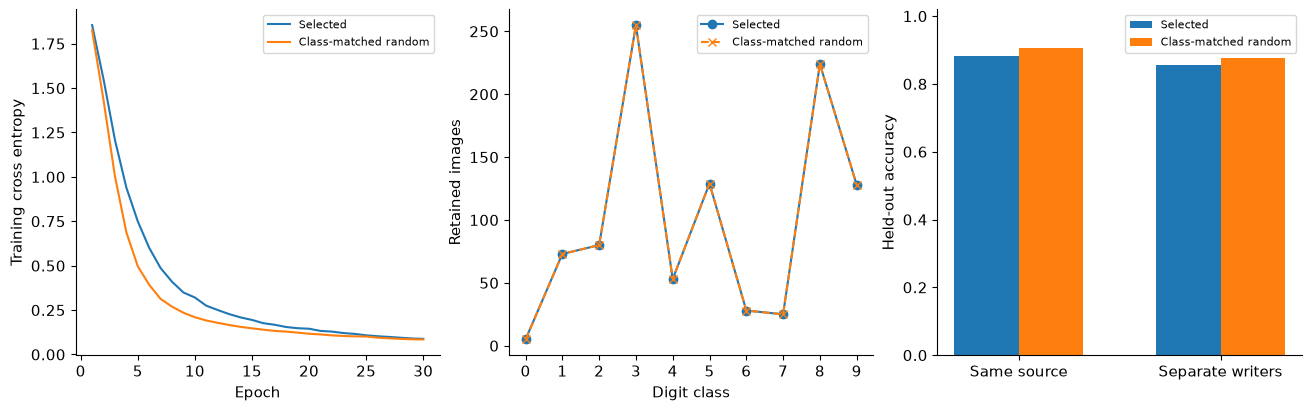

In [60]:
def retraining_play(train, mapping, evaluation, methods, region='ambiguous', size=1000, seed=166000, epochs=30):
    if region not in ('easy', 'hard', 'ambiguous'):
        raise ValueError('Choose easy, hard or ambiguous.')
    stats = mapping['statistics']['clean']['end']
    score = stats['variability' if region == 'ambiguous' else 'confidence'][0]
    selected = methods.select_indices(score, size, largest=region != 'hard').sort().values
    random = methods.matched_random_indices(train['y'], selected, seed + 1)
    indices = cart_torch.stack([selected, random])
    run = methods.train_ensemble(train['x'][indices], train['y'][indices], [seed, seed], epochs=epochs, record=False)
    return dict(region=region, indices=indices, run=run, evaluation={name: methods.evaluate_models(run['parameters'], split['x'], split['y']) for name, split in evaluation.items()}, exploratory_holdout_reuse=True)

region = 'ambiguous'

retained = 1000

seed = 166000

epochs = 30

cart_play = retraining_play(cart_train, mapping, evaluation, cart_methods, region, retained, seed, epochs)

cart_torch.save(cart_play, native_directory / 'play.pt')

cart_fig, cart_axes = cart_plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

for cart_index, cart_label in enumerate(('Selected', 'Class-matched random')):
    cart_axes[0].plot(range(1, epochs + 1), cart_play['run']['loss'][:, cart_index], label=cart_label)
    cart_counts = cart_torch.bincount(cart_train['y'][cart_play['indices'][cart_index]], minlength=10)
    cart_axes[1].plot(range(10), cart_counts, 'o-' if cart_index == 0 else 'x--', label=cart_label)
    results = [float(cart_play['evaluation'][name]['accuracy'][cart_index]) for name in ('same_source', 'separate_writers')]
    cart_axes[2].bar(cart_np.arange(2) + (cart_index - 0.5) * 0.32, results, width=0.32, label=cart_label)

cart_axes[0].set(xlabel='Epoch', ylabel='Training cross entropy')

cart_axes[1].set(xlabel='Digit class', ylabel='Retained images')

cart_axes[1].set_xticks(range(10))

cart_axes[2].set_xticks(range(2), labels=['Same source', 'Separate writers'])

cart_axes[2].set(ylabel='Held-out accuracy', ylim=(0, 1.02))

for cart_ax in cart_axes:
    cart_ax.legend(fontsize=8)

cart_show_figure(cart_fig, 'cartography_real_play')

## What did the map tell us?

You implemented the coordinates, a training loop that records both logging
conventions, a controlled noise-diagnosis experiment, and actual retraining from
selected data. The result separates three questions that can otherwise blur
together: whether an example is learned late, whether its label is wrong, and
whether keeping it improves a new model.

Confidence was fairly stable across mapping seeds here, while variability and
selection membership were less stable. Low confidence found many injected label
errors, yet it also selected useful clean training examples. High variability
was not a universal best-subset rule. Class coverage and optimizer-update count
both mattered, and neither alone explained every difference.

### Limitations and further research

- The MLP and linear model are small digit classifiers. The separate-writer
  split tests a particular source-defined generalization setting, not the paper's
  independently collected language challenge sets.
- Noise is a fixed cyclic 10% corruption with known original labels. Real label
  ambiguity, systematic annotation conventions and naturally occurring errors
  require a separate audit; the detector's measured precision does not transfer
  automatically.
- There are five fixed mapping seeds and five retraining seeds. Selection uses
  one prescribed map. The result does not average across independent datasets,
  mapping-seed choices or alternative optimizers.
- The primary comparisons fix epochs. The 720-update control covers only the
  one-third ambiguous subset and its matched random controls. Mapping itself
  also costs a full training run; pruning does not make this initial cost vanish.
- A map loses temporal order and depends on the probability scale. It is not an
  estimate of an example's causal contribution, a posterior uncertainty measure,
  or evidence that an input is inherently easy or ambiguous.

For deeper self-study, explain why permuting epochs leaves every coordinate
unchanged but may change a forgetting count. Compare the same top-1,000 region
across all five mapping seeds. Design a class-stratified selection rule, fix its
budget and training schedule in advance, then reserve new evaluation data before
claiming an improvement. Identify which assumptions would have to change to
apply this notebook to fine-tuning a language model.

## Reading

- Swayamdipta et al. (2020), [Dataset Cartography: Mapping and Diagnosing Datasets
  with Training Dynamics](https://aclanthology.org/2020.emnlp-main.746/): start
  with Sections 2–3, then the noise experiment and Appendix A.1. Compare its
  model, task and evaluation setting with the claims supported here.
- [Authors' implementation](https://github.com/allenai/cartography): inspect
  `cartography/classification/run_glue.py` for the logging time and
  `cartography/selection/train_dy_filtering.py` for population variability.
  The code stores correctness as a count; our displayed fraction divides by epochs.
- [UCI Optical Recognition of Handwritten Digits](https://doi.org/10.24432/C50P49),
  Alpaydin and Kaynak (1998), CC BY 4.0. The frozen source manifest records every
  selected row and checksum.

### Optional reproducibility checks

The following cell repeats two full mapping runs separately and compares all
of their snapshots and final parameters with the scheduled runs. An independent
NumPy calculation checks the real-data coordinates. The earlier learner test
also compared your training loop with ordinary `torch.nn` and `torch.optim.SGD`.
These checks support the figures; they are not a substitute for interpreting them.

In [61]:
checks = cart_reference_checks(cart_train, mapping, cart_methods)

(cart_OUTPUT / 'reference_checks.json').write_text(cart_json.dumps(checks, indent=2) + '\n')

cart_summary = summarize(mapping, cart_prepared, cart_evaluated, cart_play, native_directory)

(cart_OUTPUT / 'native_summary.json').write_text(cart_json.dumps(cart_summary, indent=2) + '\n')

print('Separate full training and independent NumPy coordinate checks passed.')

print(f"Frozen experiment: {cart_summary['main_training_runs']} real training runs, {cart_summary['main_optimizer_updates']} optimizer updates, plus two separate checks and two play fits.")

Separate full training and independent NumPy coordinate checks passed.
Frozen experiment: 140 real training runs, 53550 optimizer updates, plus two separate checks and two play fits.


## Summary of 2️⃣

State the scientific intervention, selection boundary, negative controls and evaluation unit before comparing this study with the other track.

# ☆ Bonus

## Compare the two protocols

Which result estimates a relationship across different subset-trained classifiers, and which uses histories within a training run? Explain why an epoch, seed, query or image pair cannot automatically count as an independent experimental unit. Design a new contrast on paper before changing the existing frozen experiments. Keep all proposed modifications exploratory until explicitly adopted.